# Task 4 – Teil 1: Baseline und Modellverständnis

**Ziel:** Das unveränderte CIGRE-Mittelspannungsnetz ohne dezentrale Erzeuger (`with_der=False`) wird als Referenz beschrieben, mit einem AC-Lastfluss berechnet und für alle Stellungen der Trennschalter S1 bis S3 ausgewertet. Am Ende steht ein reproduzierbares Referenzszenario, von dem alle weiteren Teilaufgaben ausgehen.

**Aufbau:**

1. Das unveränderte CIGRE-MV-Netz: Topologie, Betriebsmittel, Nennspannungen, Betriebspunkt
2. Statischer AC-Lastfluss der Baseline mit Konvergenzprüfung und Vorzeichenkonventionen
3. Alle Schalterstellungen S1–S3 im statischen Lastfluss
4. Alle Schalterstellungen S1–S3 als Zeitreihe über 12 typische Wochen
5. Festlegung des Referenzszenarios
6. Zusammenfassung und Literaturabgleich

Die Eingangsdaten (BDEW-Lastprofile, Wetterdaten, Anlagenkennlinien) sind im Notebook `Task4-Datengrundlage.ipynb` beschrieben.

## Importe

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

# Alle Module liegen im Ordner dieses Notebooks (task4)
import simulation as sim
import szenarien as sz
import netplan
import plots
from elements import Diagram, Profile
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

# Zeitreihen nur neu rechnen, wenn sich Netz, Einstellungen oder Daten geändert haben.
# False: jede Simulation wird bei jedem Durchlauf neu gerechnet.
sim.ONLY_RUN_IF_CHANGED = True

Module im Ordner `task4` (Beschreibung siehe `README.md`):

- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für Zeitreihen-Lastflüsse aus Task 3. Mit `sim.ONLY_RUN_IF_CHANGED = True` lädt `runSimulation()` die gespeicherten Ergebnisse, solange sich Netz, Einstellungen und Eingangsdaten nicht geändert haben.
- `netplan.py`: Netzplan mit Spannungen, Auslastungen und Pfeilen für die Richtung des Wirkleistungsflusses
- `szenarien.py` (neu): Schalterstellungen S1–S3, statische Lastflüsse aller Schaltzustände, Vergleichstabellen und Heatmaps
- `profiles.py`, `weather.py`, `plots.py`: Lastprofile, Wetter und Diagrammhilfen (siehe `Task4-Datengrundlage.ipynb`)

## 1 Das unveränderte CIGRE-MV-Netz

Als Referenz dient das CIGRE-MV-Benchmarknetz [13] in der pandapower-Umsetzung [14] **ohne** dezentrale Erzeuger:

```python
net = pn.create_cigre_network_mv(with_der=False)
```

Jede Untersuchung erzeugt das Netz mit dieser Funktion neu. Damit startet jeder Vergleich vom selben, unveränderten Stand.

In [2]:
def baseline_net():
    """Unverändertes CIGRE-MV-Netz ohne dezentrale Erzeuger (Referenz für alle Vergleiche)."""
    return pn.create_cigre_network_mv(with_der=False)

net = baseline_net()
net

This pandapower network includes the following parameter tables:
   - bus (15 elements)
   - load (18 elements)
   - switch (8 elements)
   - ext_grid (1 element)
   - line (15 elements)
   - trafo (2 elements)

### 1.1 Netzplan und Topologie

![CIGRE-MV-Netz ohne dezentrale Erzeuger](cigre_network_mv_der.png)

*Bild: Netzplan des CIGRE-MV-Netzes ohne dezentrale Erzeuger (`with_der=False`) aus der pandapower-Dokumentation [14], nach [13]. Quelle der Bilddatei: pandapower-Repository, `doc/pics/networks/cigre/cigre_network_mv.png` (BSD-3-Clause-Lizenz).*

**Topologie:**

- **Einspeisung:** Das externe Netz (Slack) liegt an Bus 0 (110 kV) mit fester Spannung 1,03 pu und Winkel 0°. Zwei Transformatoren 110/20 kV (Trafo 0-1, Trafo 0-12) speisen zwei getrennte 20-kV-Abgänge.
- **Abgang 1 (Bus 1 bis Bus 11, Kabel):** Der Strang Bus 1 – 2 – 3 verzweigt an Bus 3 in die Äste Bus 4 – 5 – 6 und Bus 8 – 9 – 10 – 11 (über Line 3-8) sowie Bus 7 (über Line 7-8). Zwei Maschen sind durch offene Trennschalter aufgetrennt: **S2** (Line 6-7) schließt die Masche 3 – 4 – 5 – 6 – 7 – 8 – 3, **S3** (Line 11-4) die Masche 3 – 4 – 11 – 10 – 9 – 8 – 3.
- **Abgang 2 (Bus 12 bis Bus 14, Freileitung):** Strahlennetz Bus 12 – 13 – 14.
- **Kupplung:** **S1** (Line 14-8) verbindet das Ende von Abgang 2 mit Bus 8 in Abgang 1. Mit geschlossenem S1 entsteht eine Masche über beide Transformatoren und die 110-kV-Sammelschiene.
- **Normalbetrieb:** S1, S2 und S3 sind offen. Das Netz wird **strahlenförmig** betrieben, jeder Bus wird über genau einen Weg versorgt. Die offenen Ringe dienen der Wiederversorgung bei Störungen. Das ist die übliche Betriebsweise von Mittelspannungsnetzen [16].

In [3]:
bus = net.bus[["name", "vn_kv", "type", "zone", "in_service"]].copy()
bus["Anschluss"] = ["externes Netz (Slack)" if b in set(net.ext_grid.bus) else "" for b in net.bus.index]
bus["Lasten"] = [", ".join(net.load.name[net.load.bus == b]) for b in net.bus.index]
bus.set_index("name")

,vn_kv,type,zone,in_service,Anschluss,Lasten
name,,,,,,
Bus 0,110.0,b,CIGRE_MV,True,externes Netz (Slack),
Bus 1,20.0,b,CIGRE_MV,True,,"Load R1, Load CI1"
Bus 2,20.0,b,CIGRE_MV,True,,
Bus 3,20.0,b,CIGRE_MV,True,,"Load R3, Load CI3"
Bus 4,20.0,b,CIGRE_MV,True,,Load R4
Bus 5,20.0,b,CIGRE_MV,True,,Load R5
Bus 6,20.0,b,CIGRE_MV,True,,Load R6
Bus 7,20.0,b,CIGRE_MV,True,,Load CI7
Bus 8,20.0,b,CIGRE_MV,True,,Load R8


### 1.2 Betriebsmittel

**Leitungen.** Die Kabel des Abgangs 1 haben den Typ `CABLE_CIGRE_MV`, die Freileitungen des Abgangs 2 und die Kupplung S1 den Typ `OHL_CIGRE_MV`. Die Werte stammen aus [13] in der Umsetzung von [14]. Die thermische Grenzleistung ist $S_\mathrm{th} = \sqrt{3} \cdot U_n \cdot I_\mathrm{max}$ mit $U_n$ = 20 kV.

In [4]:
line = net.line.copy()
line_tab = pd.DataFrame({
    "von": net.bus.name.loc[line.from_bus].values,
    "nach": net.bus.name.loc[line.to_bus].values,
    "Typ": line.std_type.values,
    "Art": line.type.map({"cs": "Kabel", "ol": "Freileitung"}).values,
    "Länge [km]": line.length_km.values,
    "R' [Ω/km]": line.r_ohm_per_km.values,
    "X' [Ω/km]": line.x_ohm_per_km.values,
    "C' [nF/km]": line.c_nf_per_km.values,
    "R [Ω]": (line.r_ohm_per_km * line.length_km).values,
    "X [Ω]": (line.x_ohm_per_km * line.length_km).values,
    "I_max [A]": (line.max_i_ka * 1000).values,
    "S_th [MVA]": (np.sqrt(3) * 20 * line.max_i_ka).values,
}, index=line.name.values)
sw_line = {r.element: r["name"] for _, r in net.switch[net.switch.et == "l"].iterrows() if r["name"]}
line_tab["Trennschalter"] = [sw_line.get(i, "") for i in line.index]
plots.table(line_tab, decimals=3)

,von,nach,Typ,Art,Länge [km],R' [Ω/km],X' [Ω/km],C' [nF/km],R [Ω],X [Ω],I_max [A],S_th [MVA],Trennschalter
Line 1-2,Bus 1,Bus 2,CABLE_CIGRE_MV,Kabel,2.820,0.501,0.716,151.175,1.413,2.019,145.000,5.023,
Line 2-3,Bus 2,Bus 3,CABLE_CIGRE_MV,Kabel,4.420,0.501,0.716,151.175,2.214,3.165,145.000,5.023,
Line 3-4,Bus 3,Bus 4,CABLE_CIGRE_MV,Kabel,0.610,0.501,0.716,151.175,0.306,0.437,145.000,5.023,
Line 4-5,Bus 4,Bus 5,CABLE_CIGRE_MV,Kabel,0.560,0.501,0.716,151.175,0.281,0.401,145.000,5.023,
Line 5-6,Bus 5,Bus 6,CABLE_CIGRE_MV,Kabel,1.540,0.501,0.716,151.175,0.772,1.103,145.000,5.023,
Line 7-8,Bus 7,Bus 8,CABLE_CIGRE_MV,Kabel,1.670,0.501,0.716,151.175,0.837,1.196,145.000,5.023,
Line 8-9,Bus 8,Bus 9,CABLE_CIGRE_MV,Kabel,0.320,0.501,0.716,151.175,0.160,0.229,145.000,5.023,
Line 9-10,Bus 9,Bus 10,CABLE_CIGRE_MV,Kabel,0.770,0.501,0.716,151.175,0.386,0.551,145.000,5.023,
Line 10-11,Bus 10,Bus 11,CABLE_CIGRE_MV,Kabel,0.330,0.501,0.716,151.175,0.165,0.236,145.000,5.023,
Line 3-8,Bus 3,Bus 8,CABLE_CIGRE_MV,Kabel,1.300,0.501,0.716,151.175,0.651,0.931,145.000,5.023,


**Transformatoren.** Beide Transformatoren sind gleich aufgebaut. Sie haben **keinen Stufenschalter** (`tap_pos` = NaN), die 20-kV-Spannung folgt also direkt der Belastung. Die Phasenverschiebung von 30° (`shift_degree`) entspricht der Schaltgruppe und verschiebt alle Winkel auf der 20-kV-Seite um −30°.

In [5]:
trafo_tab = net.trafo[["name", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "vkr_percent",
                       "pfe_kw", "i0_percent", "shift_degree", "tap_pos"]].set_index("name")
trafo_tab["OS-Bus"] = net.bus.name.loc[net.trafo.hv_bus].values
trafo_tab["US-Bus"] = net.bus.name.loc[net.trafo.lv_bus].values
trafo_tab["I_n US [A]"] = net.trafo.sn_mva.values / (np.sqrt(3) * net.trafo.vn_lv_kv.values) * 1000
trafo_tab

,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,i0_percent,shift_degree,tap_pos,OS-Bus,US-Bus,I_n US [A]
name,,,,,,,,,,,,
Trafo 0-1,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,NaN,Bus 0,Bus 1,721.687836
Trafo 0-12,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,NaN,Bus 0,Bus 12,721.687836


**Schalter und externes Netz.** Die drei Trennschalter (LBS) sitzen jeweils an einem Ende einer Leitung. Die Leistungsschalter (CB) an der 110-kV-Seite der Trafos sind geschlossen.

In [6]:
sw = net.switch.copy()
sw["Bus"] = net.bus.name.loc[sw.bus].values
sw["Element"] = [net.line.name.at[e] if t == "l" else net.trafo.name.at[e] for e, t in zip(sw.element, sw.et)]
sw["Art"] = sw.et.map({"l": "an Leitung", "t": "an Trafo", "b": "Bus–Bus"})
display(sw[["name", "Bus", "Element", "Art", "type", "closed"]])
net.ext_grid[["bus", "vm_pu", "va_degree", "s_sc_max_mva", "rx_max"]]

,name,Bus,Element,Art,type,closed
0,None,Bus 6,Line 6-7,an Leitung,LBS,True
1,S2,Bus 7,Line 6-7,an Leitung,LBS,False
2,S3,Bus 4,Line 11-4,an Leitung,LBS,False
3,None,Bus 11,Line 11-4,an Leitung,LBS,True
4,S1,Bus 8,Line 14-8,an Leitung,LBS,False
5,None,Bus 14,Line 14-8,an Leitung,LBS,True
6,None,Bus 0,Trafo 0-1,an Trafo,CB,True
7,None,Bus 0,Trafo 0-12,an Trafo,CB,True


,bus,vm_pu,va_degree,s_sc_max_mva,rx_max
0,0,1.03,0.0,5000.0,0.1


**Lasten (Betriebspunkt).** Die 18 Lasten sind nach [13] Wohngebiete (*residential*, `Load R…`) und Gewerbe/Industrie (*commercial/industrial*, `Load CI…`). Die angegebenen Werte sind Bemessungs- bzw. Höchstleistungen. Im statischen Lastfluss arbeiten alle Lasten gleichzeitig mit diesen Werten. Die großen Lasten an Bus 1 und Bus 12 (je 15 MW Haushalt und 5 MW Gewerbe) bilden weitere, nicht einzeln modellierte Abgänge an den 20-kV-Sammelschienen nach. Vorzeichen: `p_mw` > 0 bedeutet Bezug (Verbraucherzählpfeilsystem).

In [7]:
load_tab = net.load[["name", "bus", "p_mw", "q_mvar"]].copy()
load_tab["Bus"] = net.bus.name.loc[load_tab.bus].values
load_tab["S [MVA]"] = np.hypot(load_tab.p_mw, load_tab.q_mvar)
load_tab["cos φ"] = load_tab.p_mw / load_tab["S [MVA]"]
load_tab["Art"] = ["Wohngebiet (R)" if n.startswith("Load R") else "Gewerbe/Industrie (CI)" for n in load_tab.name]
load_tab = load_tab.drop(columns="bus").set_index("name")
display(plots.table(load_tab, decimals=3))
print(f"Summe: P = {net.load.p_mw.sum():.2f} MW, Q = {net.load.q_mvar.sum():.2f} Mvar, "
      f"cos φ = {net.load.p_mw.sum() / np.hypot(net.load.p_mw.sum(), net.load.q_mvar.sum()):.3f}")
print(f"davon Bus 1 und Bus 12: {net.load.p_mw[net.load.bus.isin([1, 12])].sum():.2f} MW")

,p_mw,q_mvar,Bus,S [MVA],cos φ,Art
name,,,,,,
Load R1,14.994,3.045,Bus 1,15.300,0.980,Wohngebiet (R)
Load R3,0.276,0.069,Bus 3,0.285,0.970,Wohngebiet (R)
Load R4,0.432,0.108,Bus 4,0.445,0.970,Wohngebiet (R)
Load R5,0.728,0.182,Bus 5,0.750,0.970,Wohngebiet (R)
Load R6,0.548,0.137,Bus 6,0.565,0.970,Wohngebiet (R)
Load R8,0.587,0.147,Bus 8,0.605,0.970,Wohngebiet (R)
Load R10,0.475,0.119,Bus 10,0.490,0.970,Wohngebiet (R)
Load R11,0.330,0.083,Bus 11,0.340,0.970,Wohngebiet (R)
Load R12,14.994,3.045,Bus 12,15.300,0.980,Wohngebiet (R)


Summe: P = 44.74 MW, Q = 11.04 Mvar, cos φ = 0.971
davon Bus 1 und Bus 12: 39.85 MW


## 2 Statischer AC-Lastfluss der Baseline

Der Lastfluss wird mit dem Newton-Raphson-Verfahren von pandapower gerechnet (`pp.runpp`). Die Funktion `sz.lastfluss()` fängt `LoadflowNotConverged` ab und prüft zusätzlich `net.converged`. Nur konvergierte Ergebnisse werden ausgewertet.

**Vorzeichenkonventionen und Bezugsgrößen** (pandapower [14], [17]):

| Ergebnisgröße | Einheit | Bezug / Vorzeichen |
|---|---|---|
| `res_bus.vm_pu` | pu | Spannungsbetrag bezogen auf die Nennspannung des Busses (`vn_kv`: 110 kV bzw. 20 kV) |
| `res_bus.va_degree` | ° | Spannungswinkel bezogen auf den Slack (Bus 0 = 0°); die 20-kV-Seite enthält die Trafo-Phasenverschiebung von −30° |
| `res_bus.p_mw` | MW | Verbraucherzählpfeil: > 0 Bezug am Bus; in den Tabellen hier als Einspeisung = −`p_mw` |
| `res_line.p_from_mw`, `p_to_mw` | MW | Leistung, die am jeweiligen Ende **in** die Leitung fließt; `p_from_mw` > 0: Fluss von `from_bus` nach `to_bus` |
| `res_line.i_ka` | kA | größerer der beiden Endströme |
| `res_line.loading_percent` | % | `i_ka` bezogen auf `max_i_ka · df · parallel` |
| `res_line.pl_mw` | MW | Wirkverluste der Leitung = `p_from_mw + p_to_mw` |
| `res_trafo.p_hv_mw` | MW | Leistung, die auf der OS-Seite in den Trafo fließt; > 0: Fluss 110 kV → 20 kV |
| `res_trafo.loading_percent` | % | Scheinleistung bezogen auf `sn_mva` |
| `res_ext_grid.p_mw` | MW | > 0: Bezug aus dem vorgelagerten Netz, < 0: Rückspeisung |
| `res_load.p_mw` / `res_sgen.p_mw` | MW | Last: > 0 Bezug; Erzeuger: > 0 Einspeisung |

In [8]:
base = sz.lastfluss(baseline_net())
assert base["converged"], "Baseline-Lastfluss nicht konvergiert"
print(f"Konvergiert: ja, {base['iterations']} Newton-Raphson-Iterationen")
base["bilanz"].round(4).to_frame("Wert")

Konvergiert: ja, 4 Newton-Raphson-Iterationen


,Wert
Last P [MW],44.7421
Erzeugung P [MW],0.0000
Bezug ext. Netz P [MW],45.0457
Bezug ext. Netz Q [Mvar],16.3414
Verluste Leitungen [MW],0.2337
Verluste Trafos [MW],0.0698
Verluste gesamt [MW],0.3036
Verluste [% der Last],0.6785


**Busse:** Spannungsbetrag, Spannung in kV, Winkel und eingespeiste Wirkleistung je Bus.

In [9]:
bus_res = base["bus"].copy()
bus_res["Abweichung [%]"] = (bus_res.vm_pu - 1) * 100
bus_res["Winkel ohne Trafo-Verschiebung [°]"] = np.where(bus_res["U_n [kV]"] < 100, bus_res.va_degree + 30, bus_res.va_degree)
plots.table(bus_res, decimals=4)

,U_n [kV],vm_pu,U [kV],va_degree,P_einspeisung [MW],Abweichung [%],Winkel ohne Trafo-Verschiebung [°]
Bus 0,110.0000,1.0300,113.3000,0.0000,45.0457,3.0000,0.0000
Bus 1,20.0000,0.9920,19.8394,-36.5568,-19.8390,-0.8028,-6.5568
Bus 2,20.0000,0.9681,19.3629,-37.6042,-0.0000,-3.1853,-7.6042
Bus 3,20.0000,0.9310,18.6192,-39.3310,-0.5017,-6.9039,-9.3310
Bus 4,20.0000,0.9291,18.5820,-39.4350,-0.4317,-7.0902,-9.4350
Bus 5,20.0000,0.9278,18.5565,-39.5066,-0.7275,-7.2177,-9.5066
Bus 6,20.0000,0.9263,18.5264,-39.5918,-0.5480,-7.3679,-9.5918
Bus 7,20.0000,0.9251,18.5024,-39.5896,-0.0765,-7.4878,-9.5896
Bus 8,20.0000,0.9254,18.5081,-39.5790,-0.5868,-7.4596,-9.5790
Bus 9,20.0000,0.9244,18.4884,-39.6192,-0.5738,-7.5578,-9.6192


**Leitungen:** Wirkleistungsfluss am Anfang und Ende, Blindleistung, Strom, Auslastung und Verluste.

In [10]:
line_res = base["line"].copy()
line_res["i [A]"] = line_res.i_ka * 1000
line_res["Verluste [kW]"] = line_res.pl_mw * 1000
plots.table(line_res.drop(columns=["i_ka", "pl_mw"]), decimals=3)

,von,nach,p_from_mw,q_from_mvar,p_to_mw,max_i_ka,loading_percent,i [A],Verluste [kW]
Line 1-2,Bus 1,Bus 2,4.549,1.504,-4.466,0.145,96.483,139.900,82.686
Line 2-3,Bus 2,Bus 3,4.466,1.438,-4.336,0.145,96.959,140.590,130.700
Line 3-4,Bus 3,Bus 4,1.712,0.387,-1.709,0.145,37.581,54.492,2.719
Line 4-5,Bus 4,Bus 5,1.278,0.284,-1.276,0.145,28.091,40.732,1.394
Line 5-6,Bus 5,Bus 6,0.549,0.109,-0.548,0.145,12.123,17.578,0.708
Line 7-8,Bus 7,Bus 8,-0.076,-0.047,0.077,0.145,1.937,2.808,0.017
Line 8-9,Bus 8,Bus 9,1.449,0.572,-1.448,0.145,33.551,48.649,1.137
Line 9-10,Bus 9,Bus 10,0.874,0.220,-0.873,0.145,19.476,28.241,0.920
Line 10-11,Bus 10,Bus 11,0.330,0.069,-0.330,0.145,7.294,10.576,0.055
Line 3-8,Bus 3,Bus 8,2.122,0.731,-2.112,0.145,48.144,69.808,9.492


In [11]:
base["trafo"].round(3)

,p_hv_mw,q_hv_mvar,p_lv_mw,loading_percent,pl_mw
Trafo 0-1,24.429,9.227,-24.388,101.411,0.041
Trafo 0-12,20.617,7.115,-20.588,84.698,0.029


**Diagramme:** Spannungsbetrag und Spannungswinkel aller Busse, Auslastung aller Leitungen mit Grenze 100 % und Wirkleistungsfluss mit Vorzeichen.

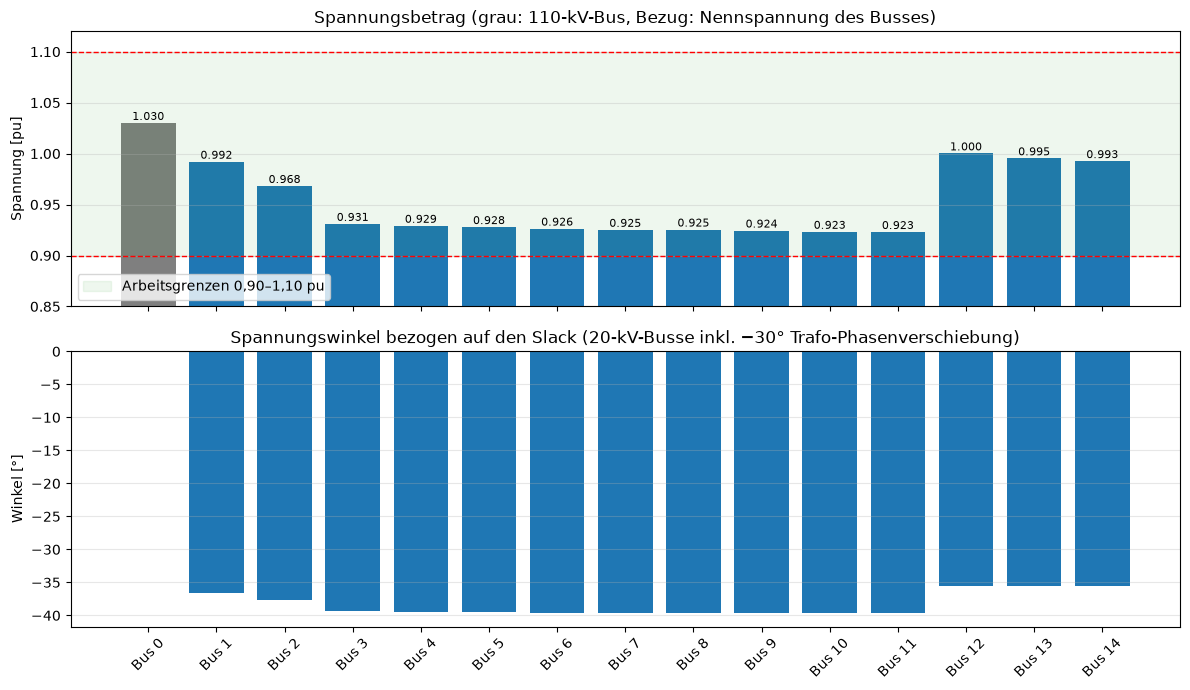

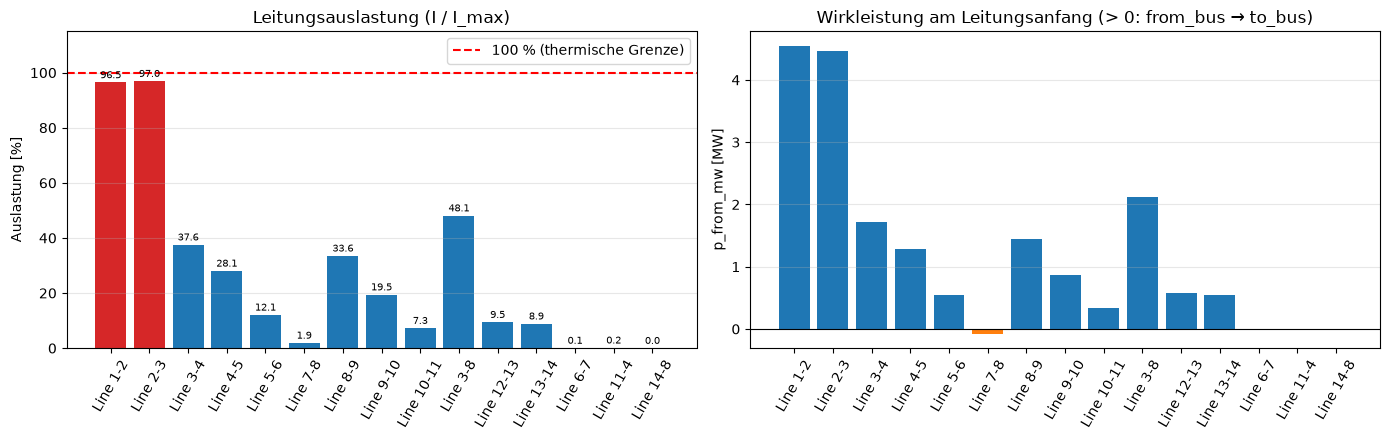

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
names = bus_res.index
c = ["tab:gray" if u > 100 else "tab:blue" for u in bus_res["U_n [kV]"]]
axes[0].bar(names, bus_res.vm_pu, color=c)
axes[0].axhspan(0.9, 1.1, color="tab:green", alpha=0.08, label="Arbeitsgrenzen 0,90–1,10 pu")
for v in (0.9, 1.1):
    axes[0].axhline(v, color="red", ls="--", lw=1)
for x, v in enumerate(bus_res.vm_pu):
    axes[0].text(x, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
axes[0].set_ylim(0.85, 1.12)
axes[0].set_ylabel("Spannung [pu]")
axes[0].set_title("Spannungsbetrag (grau: 110-kV-Bus, Bezug: Nennspannung des Busses)")
axes[0].legend(loc="lower left")
axes[1].bar(names, bus_res.va_degree, color=c)
axes[1].set_ylabel("Winkel [°]")
axes[1].set_title("Spannungswinkel bezogen auf den Slack (20-kV-Busse inkl. −30° Trafo-Phasenverschiebung)")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lr = base["line"]
col = ["black" if v > 100 else "tab:red" if v > 80 else "tab:blue" for v in lr.loading_percent]
axes[0].bar(lr.index, lr.loading_percent, color=col)
axes[0].axhline(100, color="red", ls="--", lw=1.5, label="100 % (thermische Grenze)")
for x, v in enumerate(lr.loading_percent):
    axes[0].text(x, v + 1.5, f"{v:.1f}", ha="center", fontsize=7)
axes[0].set_ylim(0, 115)
axes[0].set_ylabel("Auslastung [%]")
axes[0].set_title("Leitungsauslastung (I / I_max)")
axes[0].legend(loc="upper right")
axes[1].bar(lr.index, lr.p_from_mw, color=["tab:orange" if v < 0 else "tab:blue" for v in lr.p_from_mw])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("p_from_mw [MW]")
axes[1].set_title("Wirkleistung am Leitungsanfang (> 0: from_bus → to_bus)")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Netzplan** mit Spannungen, Auslastungen und Richtung des Wirkleistungsflusses (schwarze Pfeile auf Leitungen und Trafos):

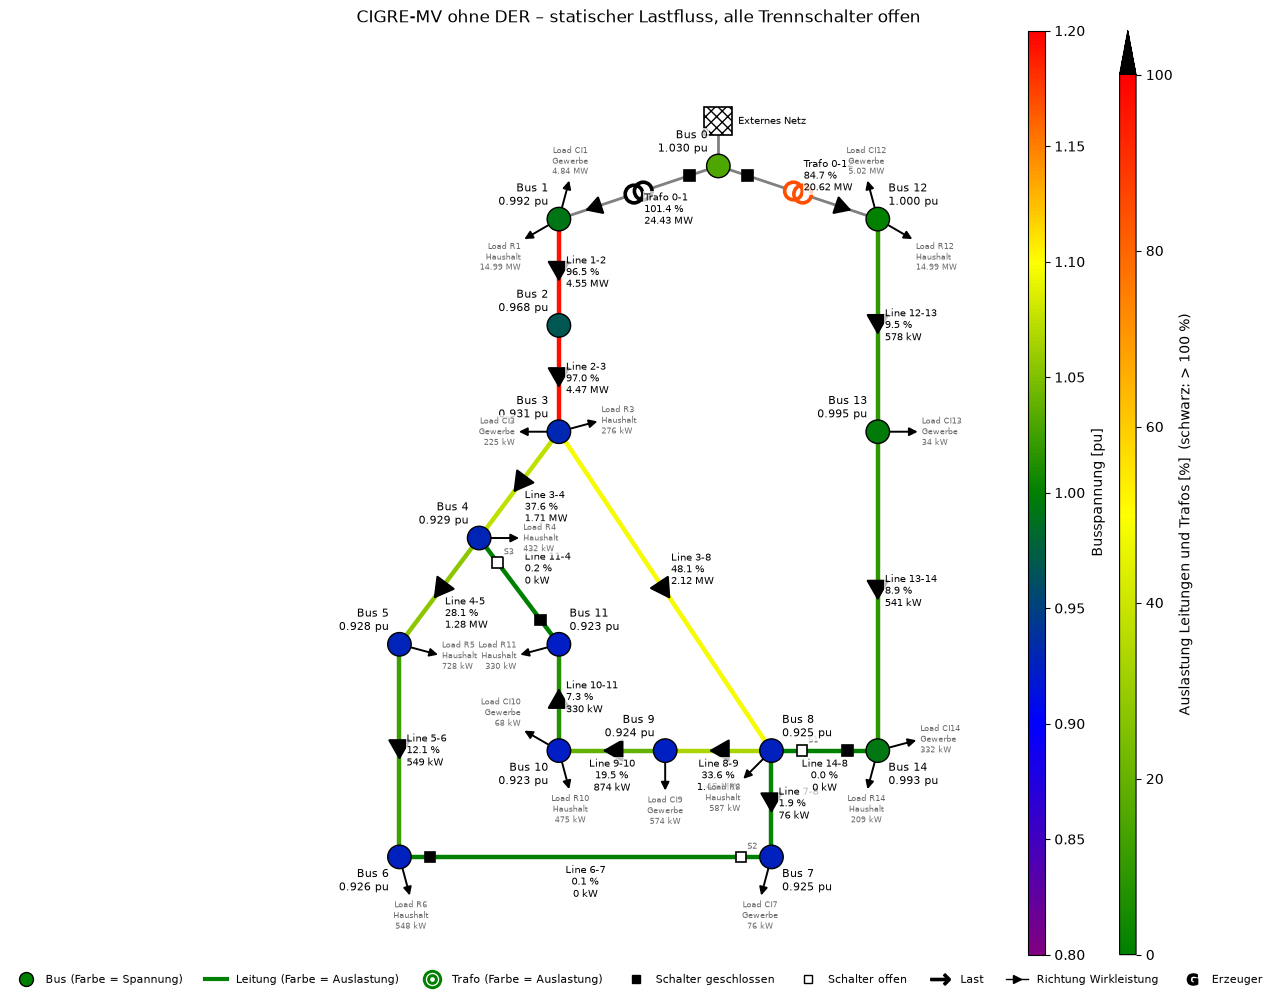

In [13]:
netplan.plot_static(base["net"], title="CIGRE-MV ohne DER – statischer Lastfluss, alle Trennschalter offen");

**Kennzahlen und Interpretation (statisch, Baseline):**

| Größe | Wert |
|---|---|
| Konvergenz | ja, 4 Iterationen |
| Last / Bezug aus 110 kV | 44,74 MW / 45,05 MW (Q: 16,3 Mvar) |
| Verluste | 0,30 MW = 0,68 % der Last (Leitungen 0,23 MW, Trafos 0,07 MW) |
| niedrigste Spannung | 0,923 pu an Bus 11 (−7,7 %) |
| höchste Leitungsauslastung | 97,0 % Line 2-3, 96,5 % Line 1-2 |
| Trafoauslastung | **101,4 %** Trafo 0-1, 84,7 % Trafo 0-12 |

- **Spannungen:** Alle Busse liegen in den Arbeitsgrenzen 0,90 bis 1,10 pu. In Abgang 1 fällt die Spannung aber um gut 7 % ab, vor allem auf den langen Kabeln Line 1-2 und Line 2-3 (zusammen 7,2 km), über die fast die gesamte Last hinter Bus 2 fließt. Abgang 2 ist schwach belastet und bleibt nahe 1,0 pu.
- **Winkel:** Ohne die −30° der Trafo-Schaltgruppe liegen die 20-kV-Busse 6,6° (Bus 1) bis 9,7° (Bus 11) hinter dem Slack. Der Winkel wächst mit der übertragenen Wirkleistung und der Reaktanz bis zum Bus. Den größten Anteil liefert die Trafo-Reaktanz (vk = 12 %).
- **Auslastung:** Line 1-2 und Line 2-3 sind fast voll ausgelastet. **Trafo 0-1 ist mit 101,4 % leicht überlastet**, weil er neben Abgang 1 die großen Ersatzlasten an Bus 1 trägt (24,4 MW, 9,2 Mvar).
- **Flussrichtung:** Alle Wirkleistung fließt von der 110-kV-Seite zu den Lasten. Line 7-8 hat ein negatives `p_from_mw`, weil die Leitung von Bus 7 nach Bus 8 definiert ist, die Last an Bus 7 aber von Bus 8 aus versorgt wird.
- **Einordnung:** Der statische Fall setzt alle 18 Lasten gleichzeitig auf ihre Höchstleistung (Gleichzeitigkeitsgrad 1). Das ist ein bewusst ungünstiger Grenzfall. Wie oft er im Jahresverlauf annähernd erreicht wird, zeigt die Zeitreihe in Abschnitt 4.

## 3 Alle Schalterstellungen S1–S3 (statisch)

Jeder der drei Trennschalter kann offen oder geschlossen sein, das ergibt 2³ = 8 Schaltzustände. Bezeichnung: Schlüssel aus drei Ziffern in der Reihenfolge S1, S2, S3 mit 1 = geschlossen. In Tabellen und Diagrammen steht die Kurzform (z. B. „S1+S3 zu“).

| Schlüssel | Kurzform | Wirkung |
|---|---|---|
| 000 | alle offen | Normalbetrieb, strahlenförmig (Baseline) |
| 001 | S3 zu | Masche 3 – 4 – 11 – 10 – 9 – 8 – 3 in Abgang 1 geschlossen |
| 010 | S2 zu | Masche 3 – 4 – 5 – 6 – 7 – 8 – 3 in Abgang 1 geschlossen |
| 011 | S2+S3 zu | beide Maschen in Abgang 1 geschlossen |
| 100 | S1 zu | Abgang 1 und 2 über Line 14-8 gekuppelt; Masche über beide Trafos und die 110-kV-Sammelschiene |
| 101, 110, 111 | Kombinationen | Kupplung und Maschen gleichzeitig |

**Was verändert wird und was konstant bleibt:** Für jeden Zustand wird das Netz mit `baseline_net()` neu erzeugt und nur die Schalterstellung geändert. Konstant bleiben alle Lasten (Bemessungswerte), die Slack-Spannung (1,03 pu), die Leitungs- und Trafoparameter und das Lastflussverfahren.

In [14]:
static = sz.statisch_alle(baseline_net)
sz.konvergenz(static)

,Schaltzustand,konvergiert,Iterationen,Hinweis
Schlüssel,,,,
000,S1 offen · S2 offen · S3 offen,ja,4,
001,S1 offen · S2 offen · S3 zu,ja,4,
010,S1 offen · S2 zu · S3 offen,ja,4,
011,S1 offen · S2 zu · S3 zu,ja,4,
100,S1 zu · S2 offen · S3 offen,ja,3,
101,S1 zu · S2 offen · S3 zu,ja,3,
110,S1 zu · S2 zu · S3 offen,ja,3,
111,S1 zu · S2 zu · S3 zu,ja,3,


Alle acht Zustände konvergieren. Damit sind alle folgenden Werte gültige Lastflussergebnisse.

**Leistungsbilanz und Kennzahlen je Schaltzustand:**

In [15]:
bil = sz.bilanzen(static)
bil_num = bil.drop(columns=["Bus U min", "Leitung mit max"]).astype(float)
display(plots.table(bil_num.T, decimals=3))
bil[["Bus U min", "Leitung mit max"]].T

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Last P [MW],44.742,44.742,44.742,44.742,44.742,44.742,44.742,44.742
Erzeugung P [MW],0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Bezug ext. Netz P [MW],45.046,45.041,45.046,45.041,44.968,44.967,44.967,44.966
Bezug ext. Netz Q [Mvar],16.341,16.333,16.341,16.332,16.080,16.080,16.077,16.076
Verluste Leitungen [MW],0.234,0.229,0.234,0.229,0.157,0.157,0.156,0.155
Verluste Trafos [MW],0.070,0.070,0.070,0.070,0.069,0.069,0.069,0.069
Verluste gesamt [MW],0.304,0.299,0.304,0.299,0.226,0.225,0.225,0.224
Verluste [% der Last],0.679,0.669,0.678,0.667,0.504,0.504,0.502,0.500
U min [pu],0.923,0.926,0.923,0.926,0.957,0.956,0.957,0.958
Leitung max [%],96.959,96.827,96.956,96.812,51.528,51.730,50.993,51.354


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus U min,Bus 11,Bus 6,Bus 11,Bus 6,Bus 6,Bus 6,Bus 11,Bus 6
Leitung mit max,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3


**Spannungsbetrag und Spannungswinkel an allen Bussen** (Zeilen = Busse, Spalten = Schaltzustände):

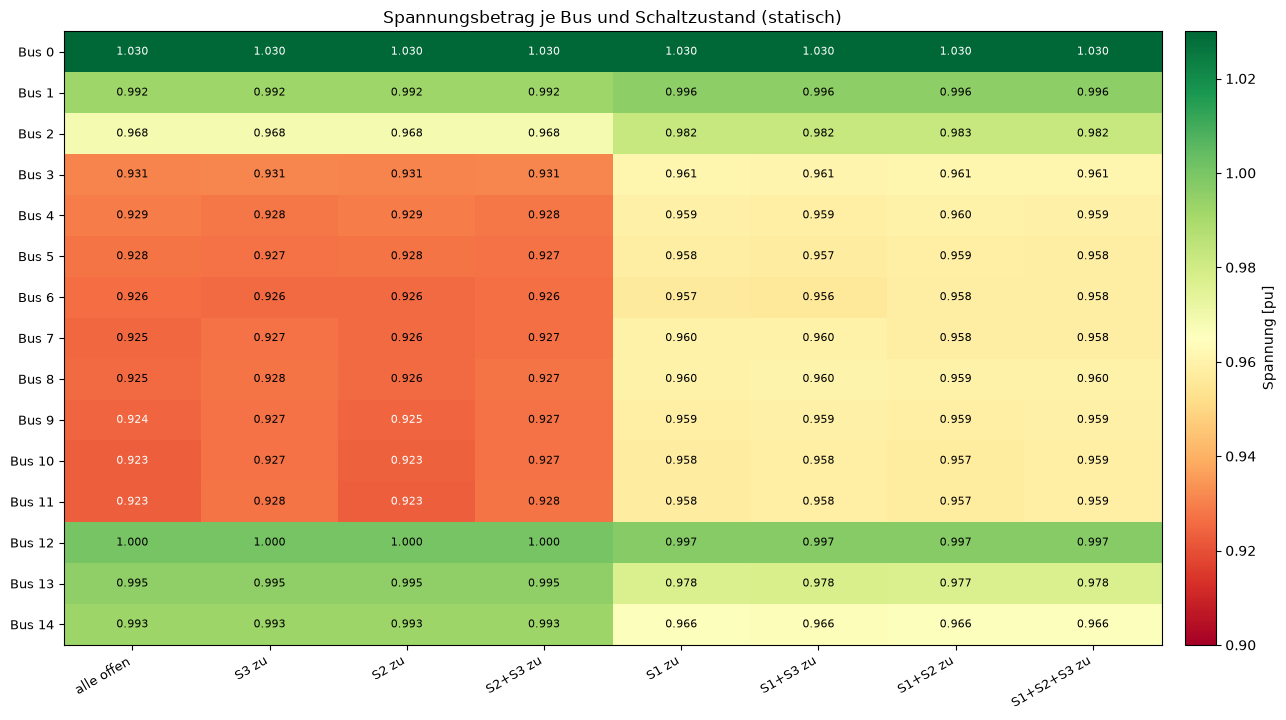

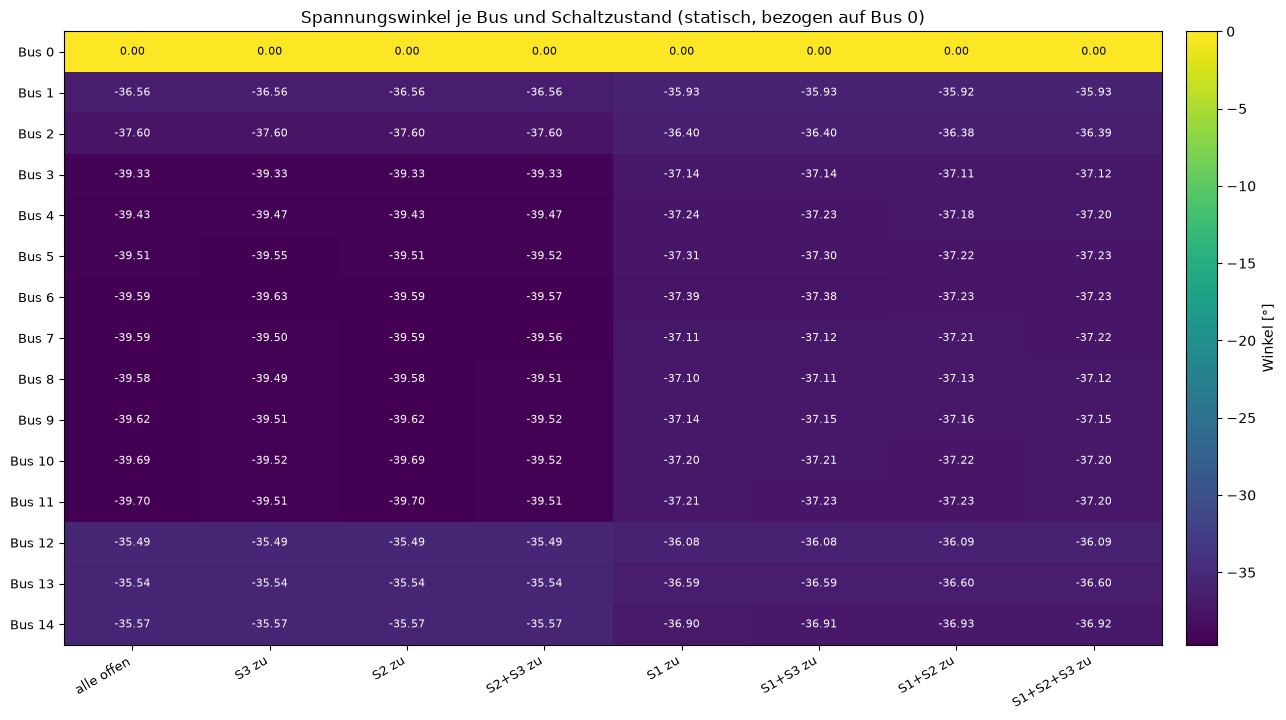

In [16]:
vm_all = sz.vergleich(static, "vm_pu")
va_all = sz.vergleich(static, "va_degree")
sz.heatmap(vm_all, "Spannungsbetrag je Bus und Schaltzustand (statisch)", "Spannung [pu]",
           cmap="RdYlGn", vmin=0.90, vmax=1.03, fmt="{:.3f}")
plt.show()
sz.heatmap(va_all, "Spannungswinkel je Bus und Schaltzustand (statisch, bezogen auf Bus 0)", "Winkel [°]",
           cmap="viridis", fmt="{:.2f}")
plt.show()

**Leitungen:** Auslastung (fett umrandet: über 100 %), Wirkleistung am Leitungsanfang (Vorzeichen = Richtung) und Strom:

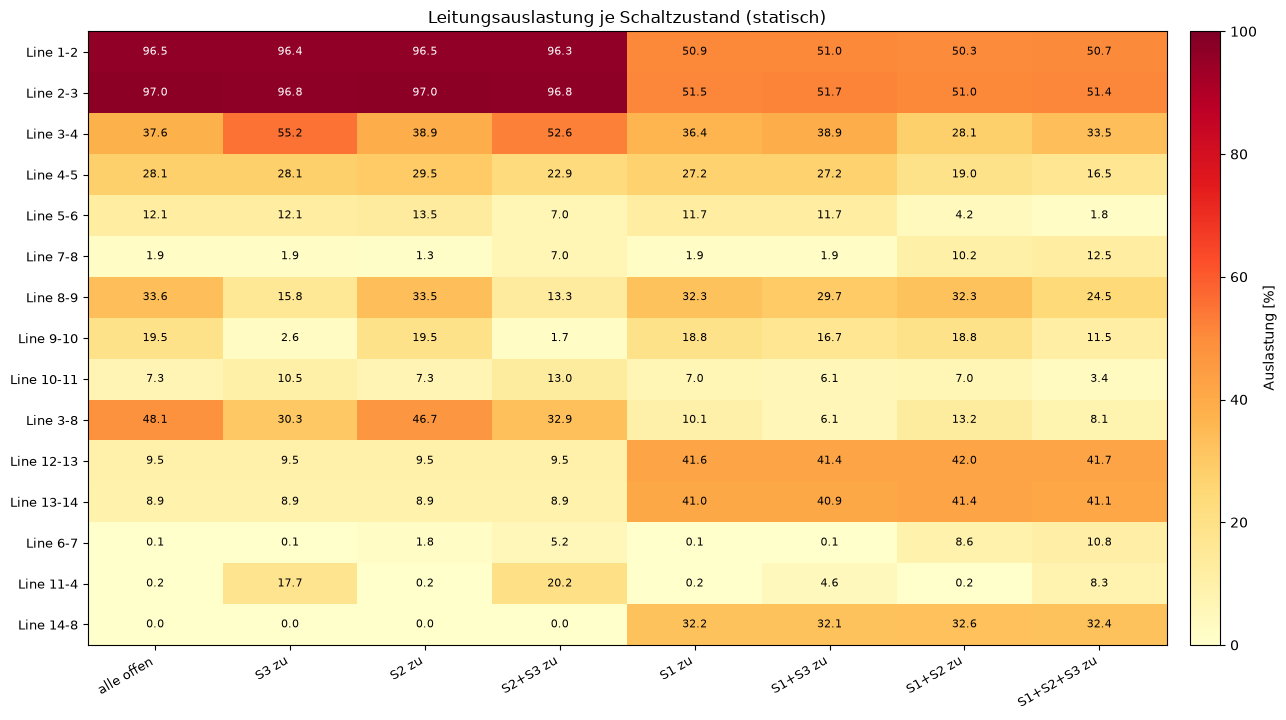

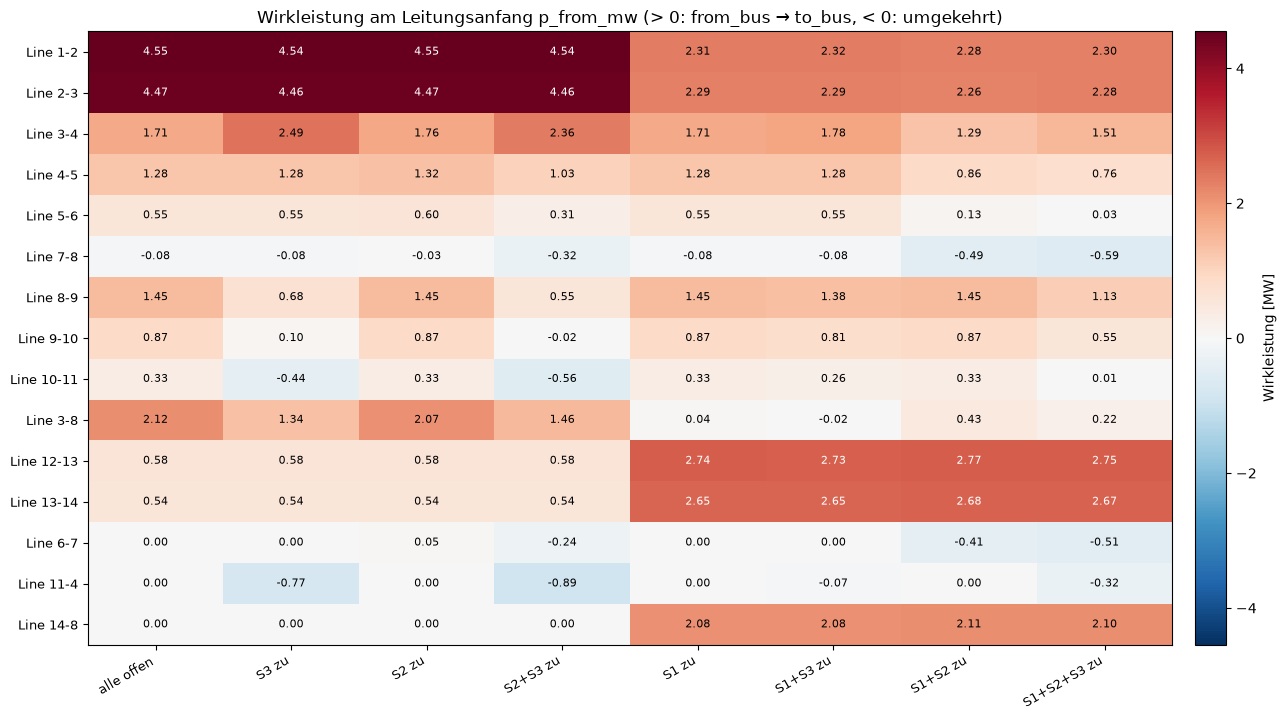

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,139.9,139.7,139.9,139.7,73.7,74.0,72.9,73.5
Line 2-3,140.6,140.4,140.6,140.4,74.7,75.0,73.9,74.5
Line 3-4,54.5,80.0,56.5,76.2,52.8,56.4,40.8,48.6
Line 4-5,40.7,40.8,42.7,33.2,39.4,39.5,27.5,24.0
Line 5-6,17.6,17.6,19.6,10.1,17.0,17.0,6.0,2.5
Line 7-8,2.8,2.8,1.9,10.2,2.7,2.7,14.8,18.1
Line 8-9,48.6,22.9,48.6,19.3,46.9,43.0,46.9,35.5
Line 9-10,28.2,3.8,28.2,2.5,27.2,24.3,27.2,16.7
Line 10-11,10.6,15.3,10.6,18.9,10.2,8.9,10.2,4.9
Line 3-8,69.8,44.0,67.7,47.7,14.6,8.9,19.2,11.8


In [17]:
ll_all = sz.vergleich(static, "loading_percent")
p_all = sz.vergleich(static, "p_from_mw")
i_all = sz.vergleich(static, "i_ka") * 1000
sz.heatmap(ll_all, "Leitungsauslastung je Schaltzustand (statisch)", "Auslastung [%]",
           cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
lim = np.nanmax(np.abs(p_all.to_numpy()))
sz.heatmap(p_all, "Wirkleistung am Leitungsanfang p_from_mw (> 0: from_bus → to_bus, < 0: umgekehrt)",
           "Wirkleistung [MW]", cmap="RdBu_r", vmin=-lim, vmax=lim, fmt="{:.2f}")
plt.show()
plots.table(i_all, decimals=1)

**Transformatoren und Verluste:**

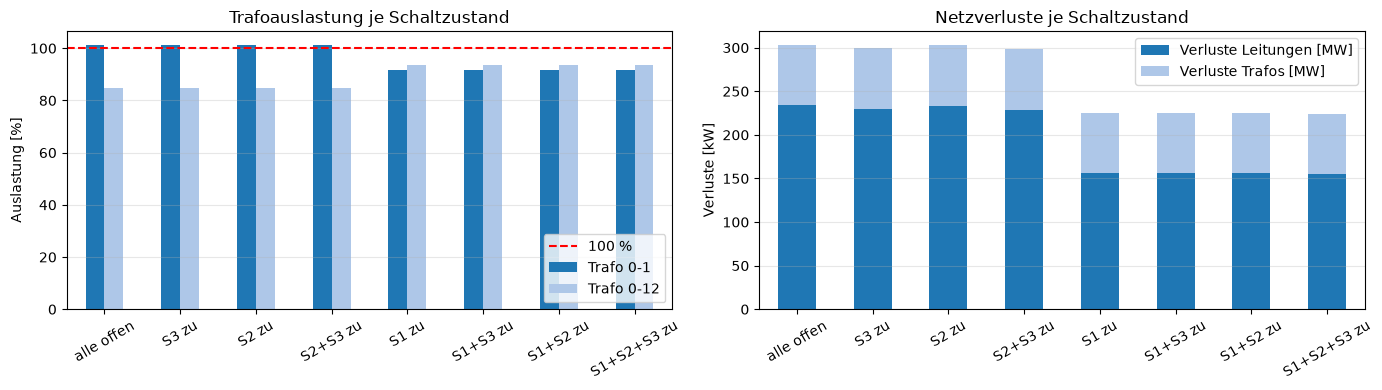

In [18]:
tr_all = pd.concat({"Auslastung [%]": sz.vergleich(static, "trafo_loading"),
                    "P OS [MW]": sz.vergleich(static, "p_hv_mw")})
display(plots.table(tr_all, decimals=2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sz.vergleich(static, "trafo_loading").T.plot.bar(ax=axes[0])
axes[0].axhline(100, color="red", ls="--", lw=1.5, label="100 %")
axes[0].set_ylabel("Auslastung [%]")
axes[0].set_title("Trafoauslastung je Schaltzustand")
axes[0].legend(loc="lower right")
(bil_num[["Verluste Leitungen [MW]", "Verluste Trafos [MW]"]] * 1000).plot.bar(stacked=True, ax=axes[1])
axes[1].set_ylabel("Verluste [kW]")
axes[1].set_title("Netzverluste je Schaltzustand")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Netzpläne aller Schaltzustände.** Die Pfeile zeigen die Richtung des Wirkleistungsflusses. Lasten und Erzeuger sind zur besseren Übersicht ausgeblendet.

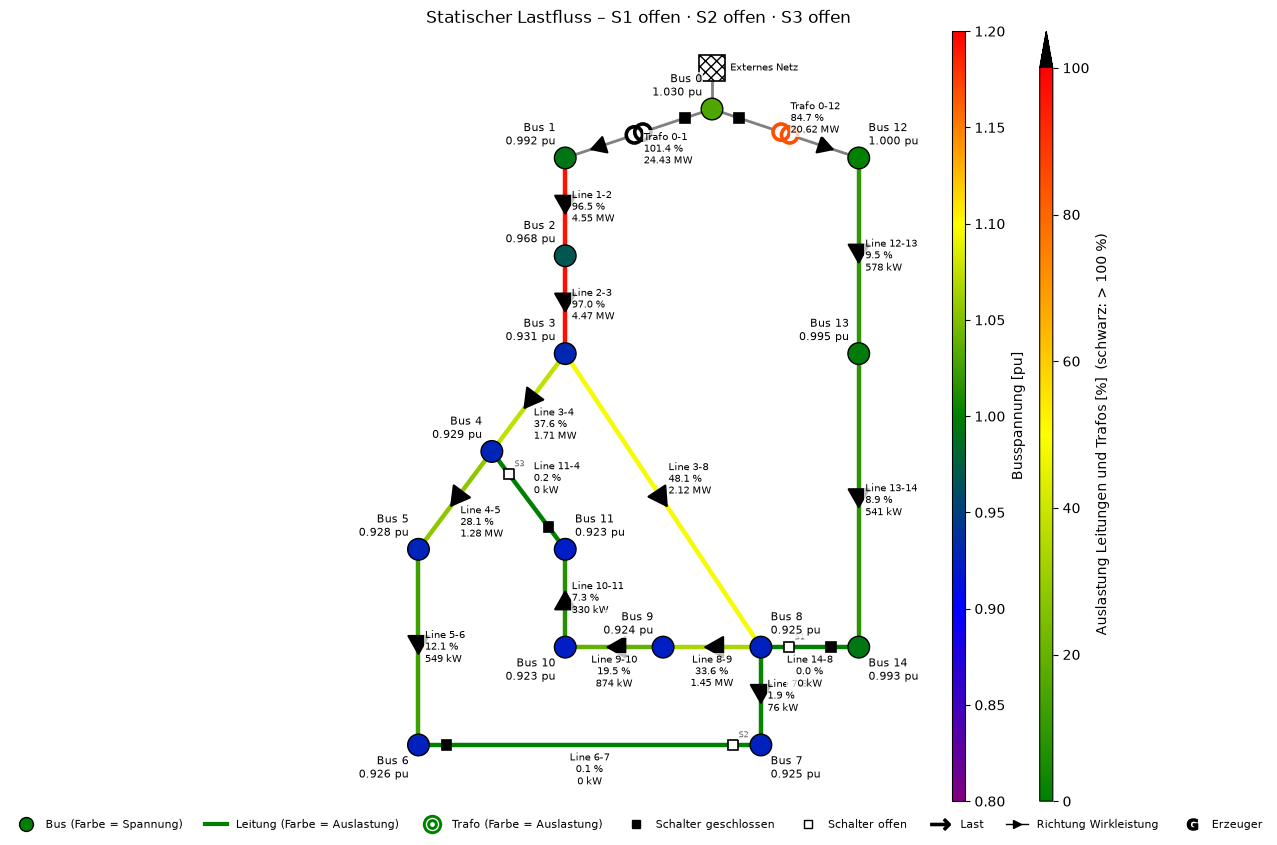

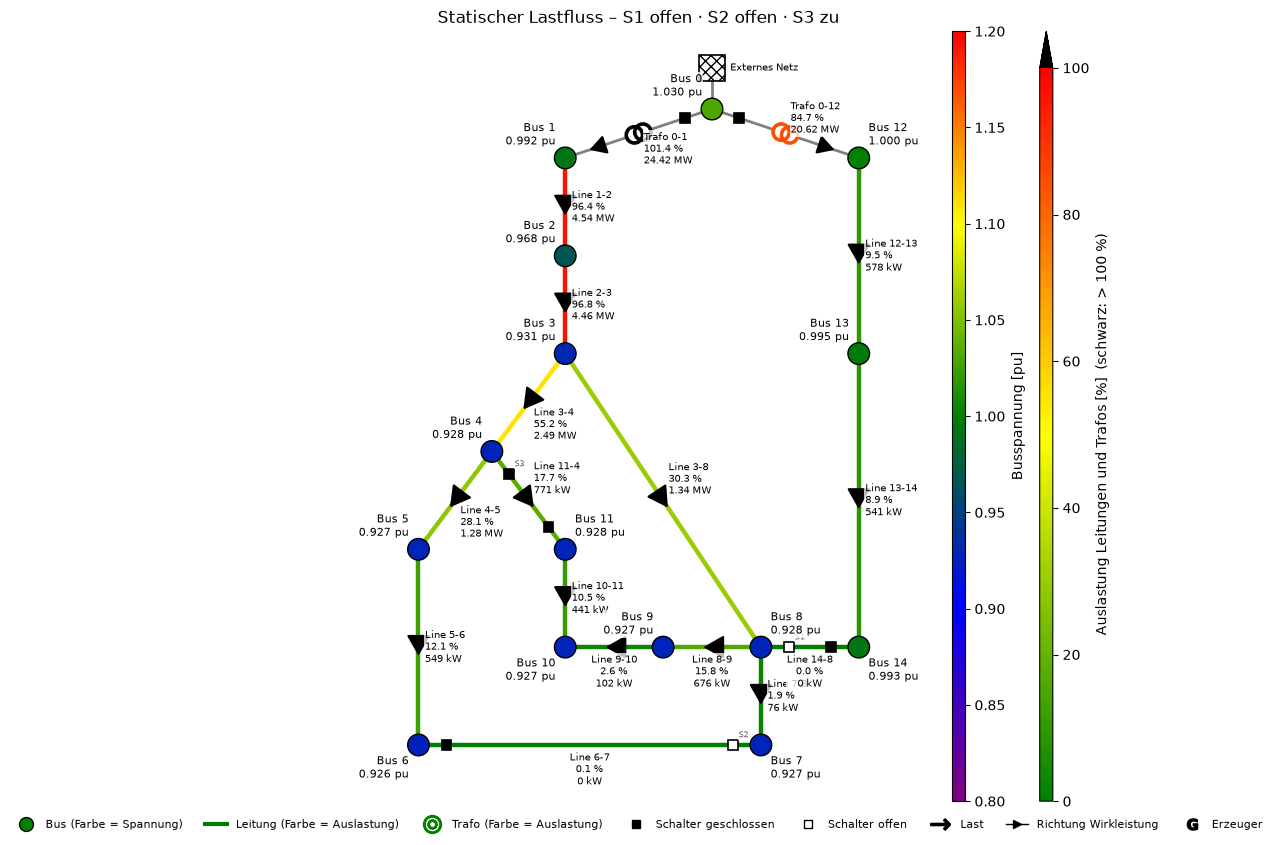

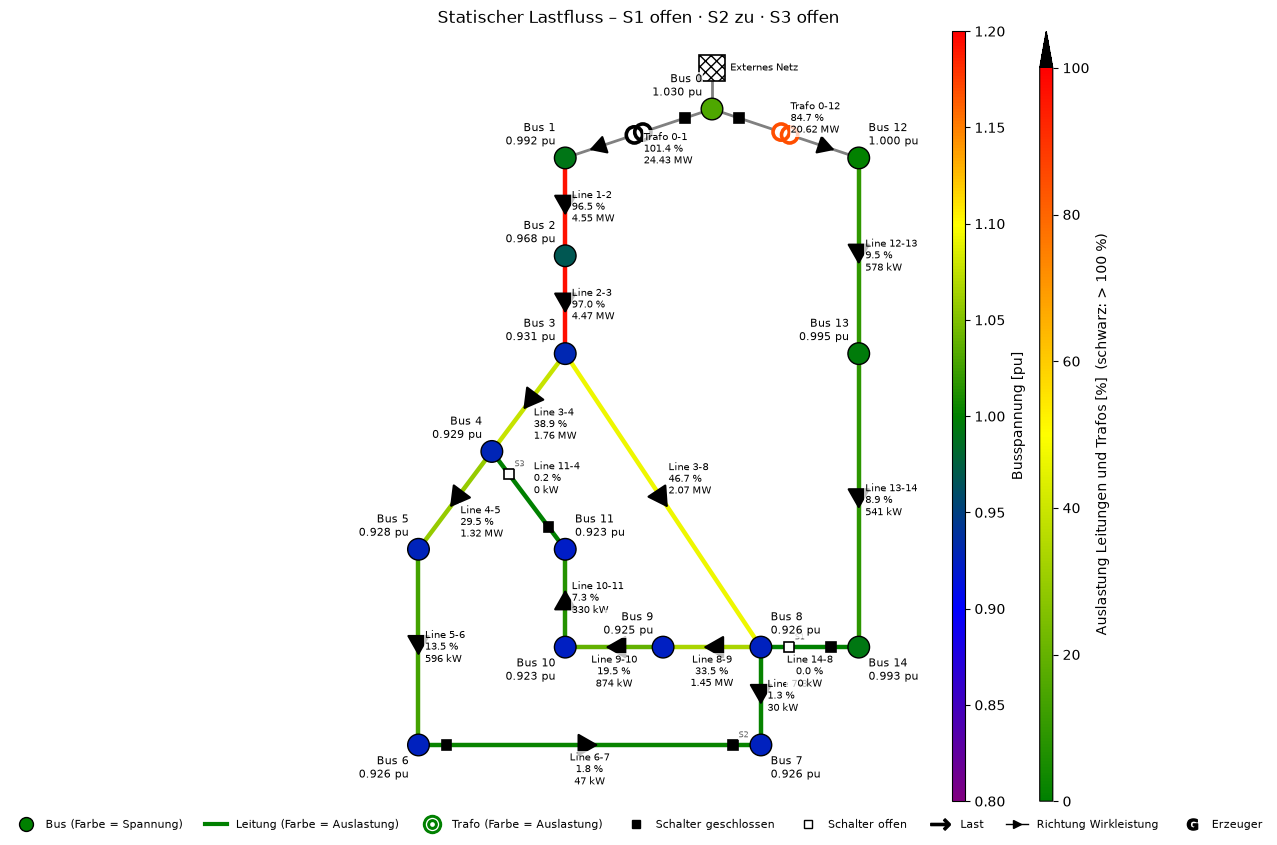

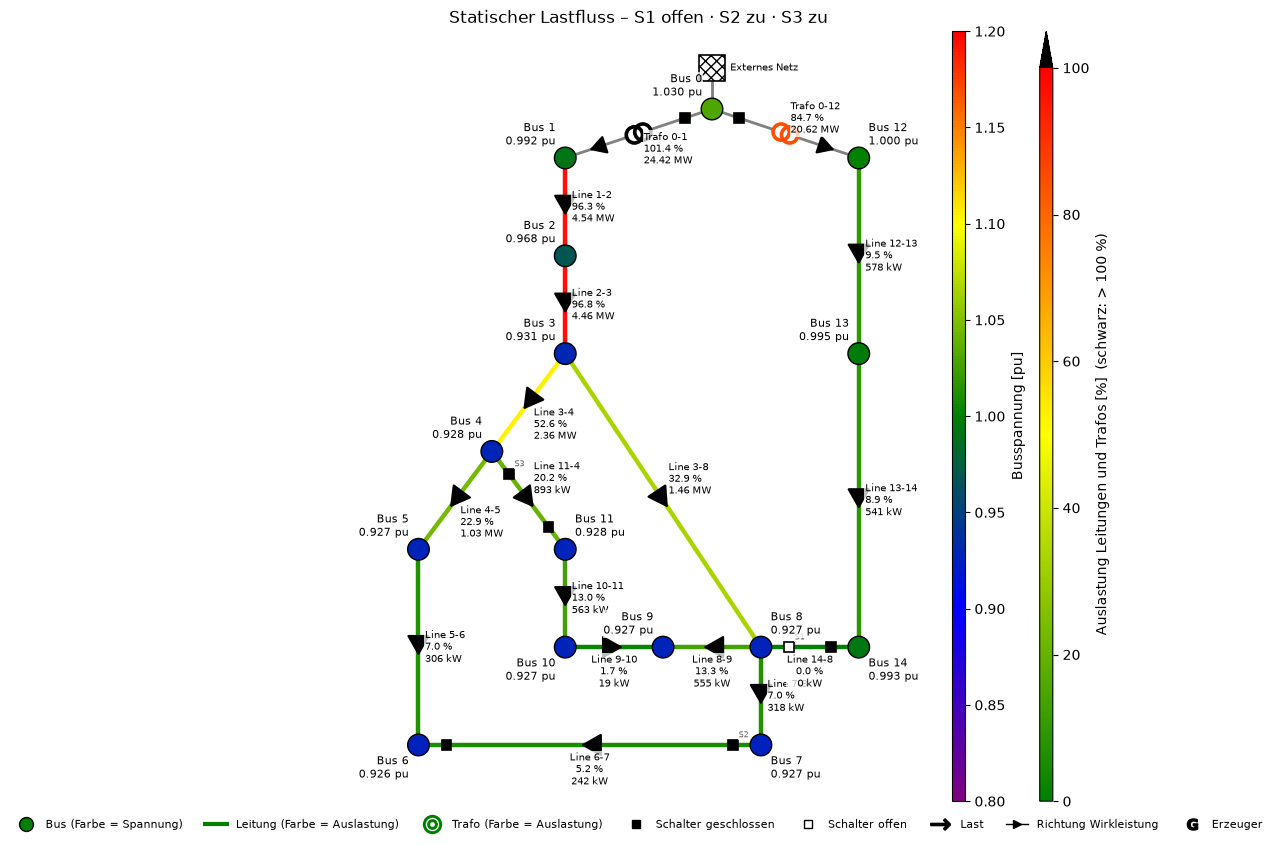

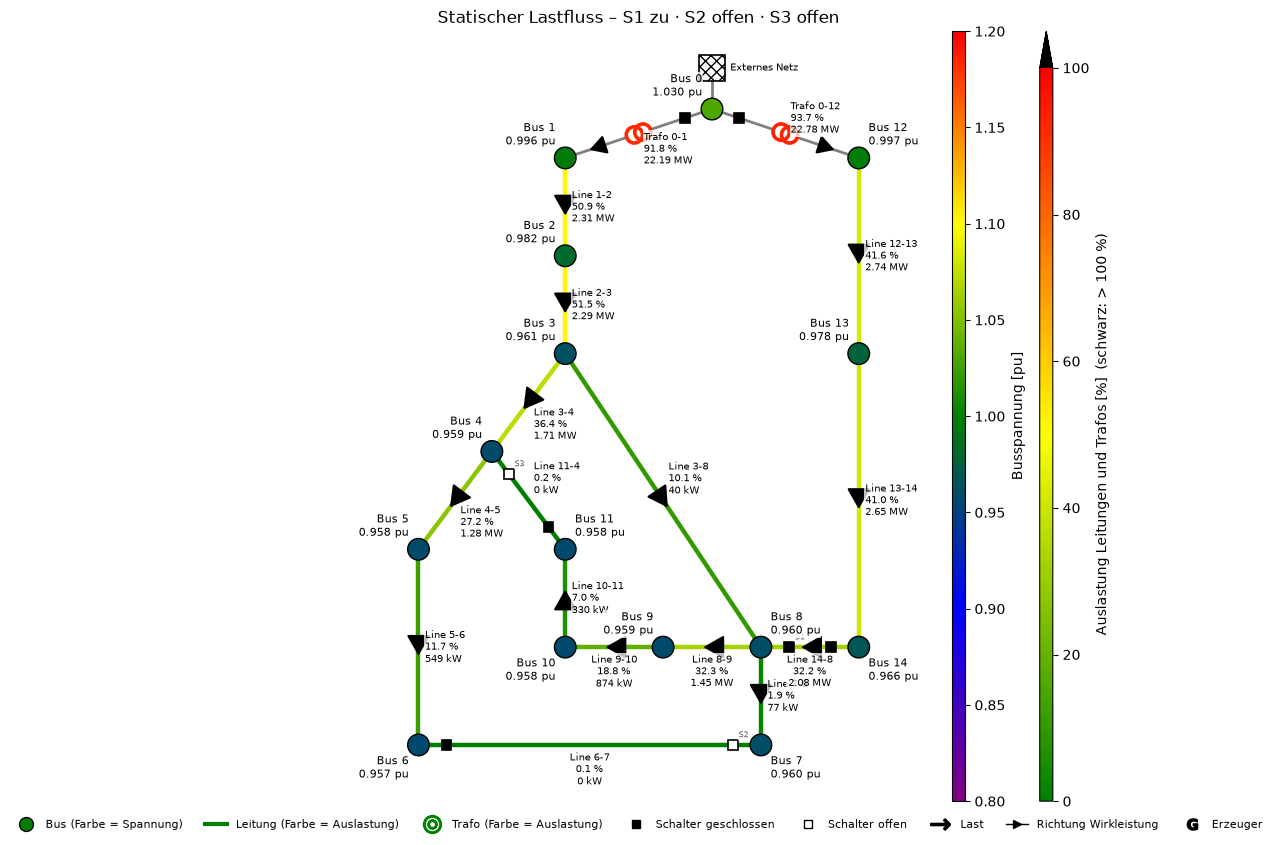

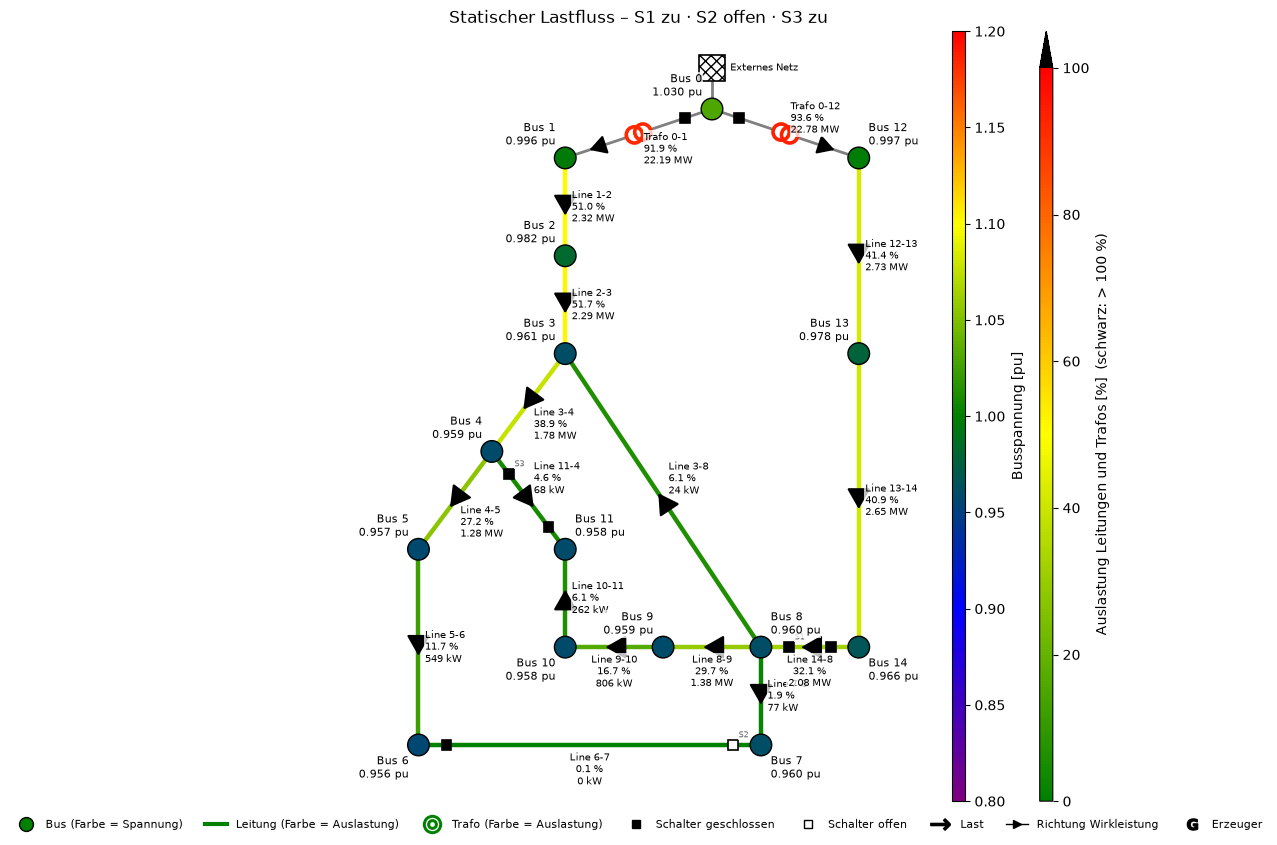

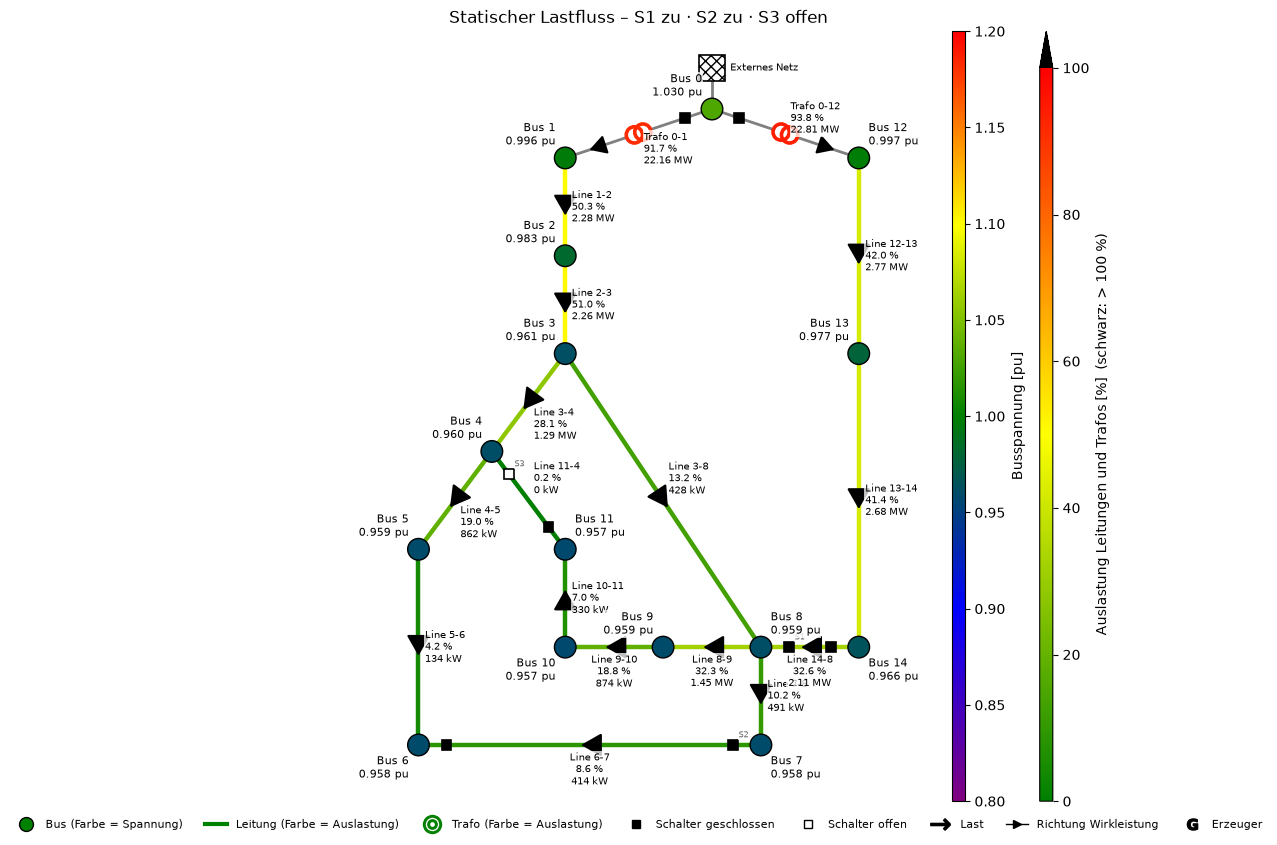

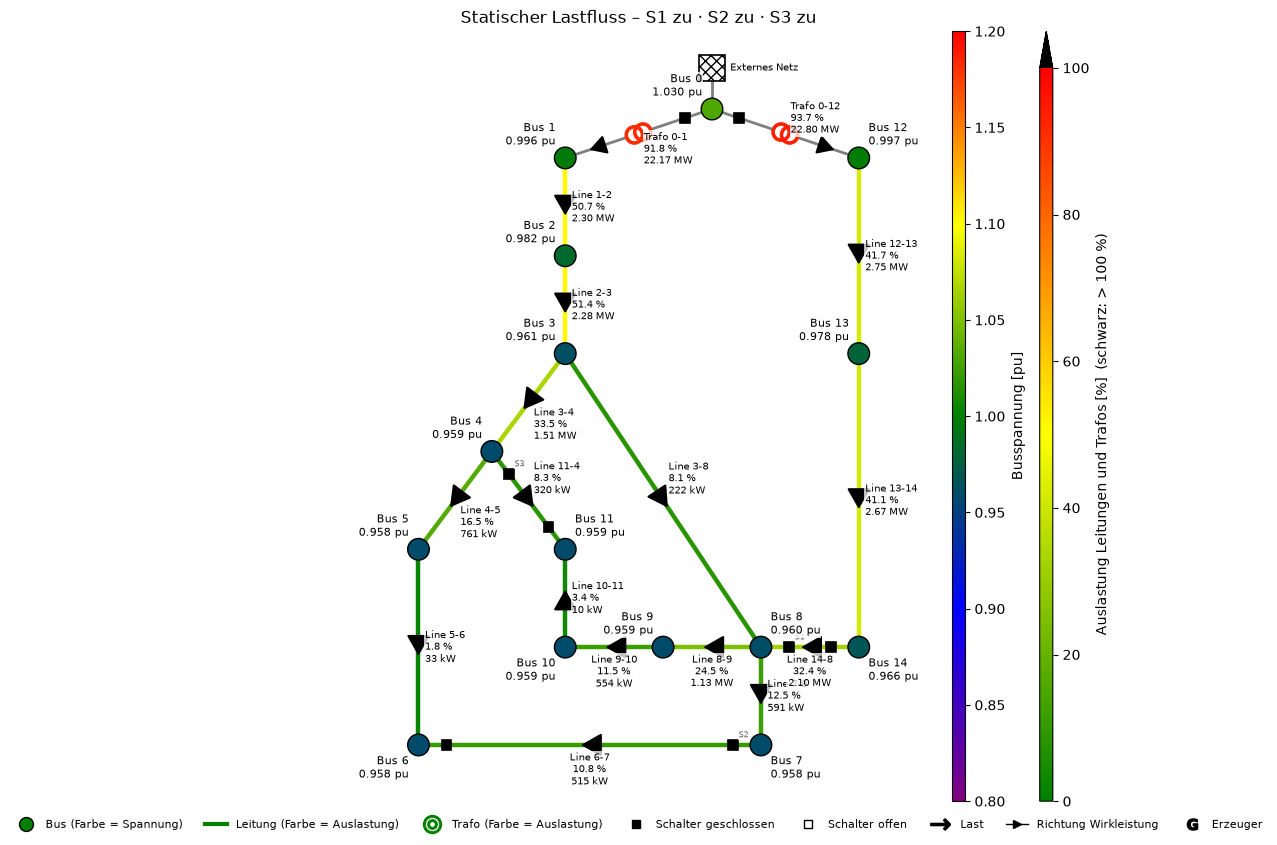

In [19]:
for key, r in static.items():
    netplan.plot_static(r["net"], title=f"Statischer Lastfluss – {sz.label(key)}", elements=False, figsize=(12, 10))

**Interpretation (statisch):**

- **S1 hat den größten Einfluss.** Mit geschlossenem S1 übernimmt Trafo 0-12 über die Freileitungen und Line 14-8 rund 2,1 MW von Abgang 1. Line 1-2 und Line 2-3 sinken von 97 % auf etwa 51 %, die niedrigste Spannung steigt von 0,923 auf 0,957 pu und die Verluste sinken um rund 26 % (0,30 → 0,23 MW). Trafo 0-1 wird von 101,4 % auf 91,8 % entlastet, Trafo 0-12 steigt von 84,7 % auf 93,7 %. Die Last verteilt sich also gleichmäßiger auf beide Transformatoren.
- **Preis der Kupplung:** In Abgang 2 sinkt die Spannung (Bus 14: 0,993 → 0,966 pu) und die Freileitungen werden mit gut 40 % statt 9 % belastet. Mit S1 entsteht außerdem eine Masche über beide Transformatoren und die 110-kV-Sammelschiene. Über sie fließt die Leistung nach den Impedanzen und nicht mehr nach einem festen Versorgungsweg. Bei einem Fehler wären beide Abgänge betroffen und die Kurzschlussleistung an den 20-kV-Sammelschienen steigt. Deshalb werden solche Kupplungen im Normalbetrieb offen gehalten [16].
- **S2 und S3 wirken nur innerhalb von Abgang 1.** Sie verändern die Aufteilung zwischen den Ästen über Bus 4 und Bus 8, aber nicht die Leistung durch Line 1-2 und Line 2-3. Deshalb bleibt deren Auslastung ohne S1 bei rund 97 %. Am stärksten verschiebt S3: Line 3-8 sinkt von 48 % auf 30 %, Line 3-4 steigt von 38 % auf 55 %. Die niedrigste Spannung verbessert sich nur um bis zu 0,003 pu.
- **Flussumkehr durch Schalten:** Mit geschlossenen Maschen ändern einige Leitungen ihre Flussrichtung, z. B. Line 10-11 mit S3 (Bus 11 wird dann von Bus 4 aus versorgt) und Line 9-10 mit S2+S3. Das zeigt sich in der Heatmap von `p_from_mw` als Vorzeichenwechsel.
- **Winkel:** Mit S1 nähern sich die Winkel beider Abgänge an (rund −37°). Weil beide Abgänge dann über die Masche gekoppelt sind, gleichen sich die Winkeldifferenzen aus.
- **Grenzen:** In keinem Zustand wird das Band 0,90 bis 1,10 pu verletzt. Eine thermische Überlastung tritt nur bei Trafo 0-1 ohne S1 auf (101,4 %).

## 4 Alle Schalterstellungen als Zeitreihe

Der statische Fall ist nur ein Betriebspunkt. Für den Jahresverlauf wird jeder Schaltzustand mit der Simulationssoftware über 12 typische Wochen stündlich gerechnet (12 × 168 = 2016 Lastflüsse je Zustand).

**Modellannahmen der Zeitreihe:**

- **Lasten und Erzeuger:** Es werden nur die 18 Lasten verwendet, die im CIGRE-Netz bereits enthalten sind. Es werden keine Lasten oder Erzeuger hinzugefügt. In `with_der=False` gibt es keine Erzeuger.
- **Profilzuordnung:** Die Zuordnung folgt den Namen aus [13] und ist nicht zufällig. `Load R…` (*residential*) erhält das BDEW-Haushaltsprofil H25 mit Dynamisierung, `Load CI…` (*commercial/industrial*) das Gewerbeprofil G25. Das übernimmt `assignProfilesByName()`.
- **Skalierung:** Der Wert `p_mw` aus [13] wird als **höchste Stundenleistung des Jahres** interpretiert. Der Jahresverbrauch jeder Last wird so berechnet, dass das Profil im Jahr 2025 genau einmal diesen Wert erreicht. Beispiel: `Load R1` (14,994 MW) entspricht rund 66 GWh/a. Die Blindleistung folgt aus dem Leistungsfaktor der Last in [13] (Wohngebiete 0,97 bzw. 0,98, Gewerbe 0,85 bzw. 0,95).
- **Gleichzeitigkeit:** Haushalte haben ihre Spitze am Winterabend, Gewerbe an Werktagen tagsüber. Die Summe aller Lasten erreicht deshalb nie die 44,7 MW des statischen Falls.

Mit `sim.ONLY_RUN_IF_CHANGED = True` (siehe Importe) werden die acht Zeitreihen nur beim ersten Durchlauf gerechnet (je etwa 40 s). Danach werden die gespeicherten Ergebnisse geladen.

In [20]:
baseline = sim.init("w4_baseline", baseline_net(), overwrite=True, assignProfiles=True)
baseline.elements("load")

18 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8


,Typ,Tabelle,Index,Bus,Profil,Skalierung
Name,,,,,,
Load R1,Last,load,0,Bus 1,HAUSHALT,66.157.911 kWh/a
Load R3,Last,load,1,Bus 3,HAUSHALT,1.219.778 kWh/a
Load R4,Last,load,2,Bus 4,HAUSHALT,1.904.566 kWh/a
Load R5,Last,load,3,Bus 5,HAUSHALT,3.209.943 kWh/a
Load R6,Last,load,4,Bus 6,HAUSHALT,2.418.157 kWh/a
Load R8,Last,load,5,Bus 8,HAUSHALT,2.589.354 kWh/a
Load R10,Last,load,6,Bus 10,HAUSHALT,2.097.163 kWh/a
Load R11,Last,load,7,Bus 11,HAUSHALT,1.455.174 kWh/a
Load R12,Last,load,8,Bus 12,HAUSHALT,66.157.911 kWh/a


In [21]:
ts = sz.zeitreihe_alle(baseline, prefix="w4_baseline")

Simulation 'w4_baseline_000': unverändert seit dem Lauf vom 2026-10-28T14:44:03 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_001': unverändert seit dem Lauf vom 2026-10-28T14:44:39 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_010': unverändert seit dem Lauf vom 2026-10-28T14:45:15 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_011': unverändert seit dem Lauf vom 2026-10-28T14:45:49 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_100': unverändert seit dem Lauf vom 2026-10-28T14:46:25 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_101': unverändert seit dem Lauf vom 2026-10-28T14:47:00 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_110': unverändert seit dem Lauf vom 2026-10-28

**Konvergenz und Kennzahlen je Schaltzustand:**

In [22]:
kz = sz.kennzahlen(ts)
text_cols = ["konvergiert", "Bus U min", "Zeitpunkt U min", "Leitung", "Zeitpunkt Leitung max"]
display(kz[text_cols])
plots.table(kz.drop(columns=text_cols).astype(float).T, decimals=3)

,konvergiert,Bus U min,Zeitpunkt U min,Leitung,Zeitpunkt Leitung max
alle offen,2016/2016,Bus 11,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S2 zu,2016/2016,Bus 11,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S2+S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S1 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00
S1+S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00
S1+S2 zu,2016/2016,Bus 11,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00
S1+S2+S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
U min [pu],0.949,0.950,0.949,0.951,0.973,0.973,0.975,0.975
U max 20 kV [pu],1.024,1.024,1.024,1.024,1.024,1.025,1.024,1.025
Stunden U < 0.9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden U > 1.1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Leitung max [%],78.638,78.584,78.637,78.563,41.096,41.152,40.536,40.792
Trafo max [%],82.694,82.682,82.693,82.678,75.685,75.678,75.798,75.745
Stunden Trafo > 100 %,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Verluste [MWh],140.880,139.118,140.818,138.825,107.526,107.425,107.044,106.603
Verluste [% der Last],0.322,0.318,0.322,0.318,0.246,0.246,0.245,0.244


Alle 8 × 2016 Lastflüsse sind konvergiert. Es gibt also keine Zeitpunkte, die gesondert interpretiert werden müssen.

**Niedrigste Spannung und höchste Winkelabweichung je Bus über das Jahr:**

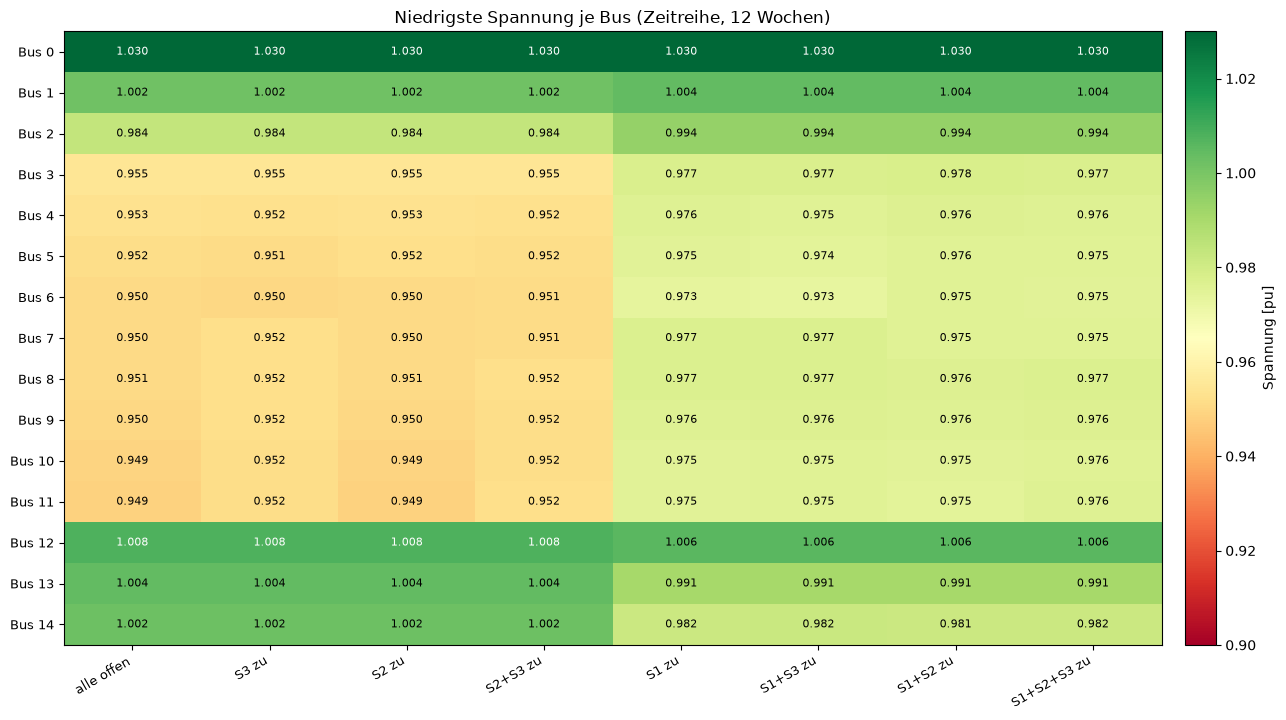

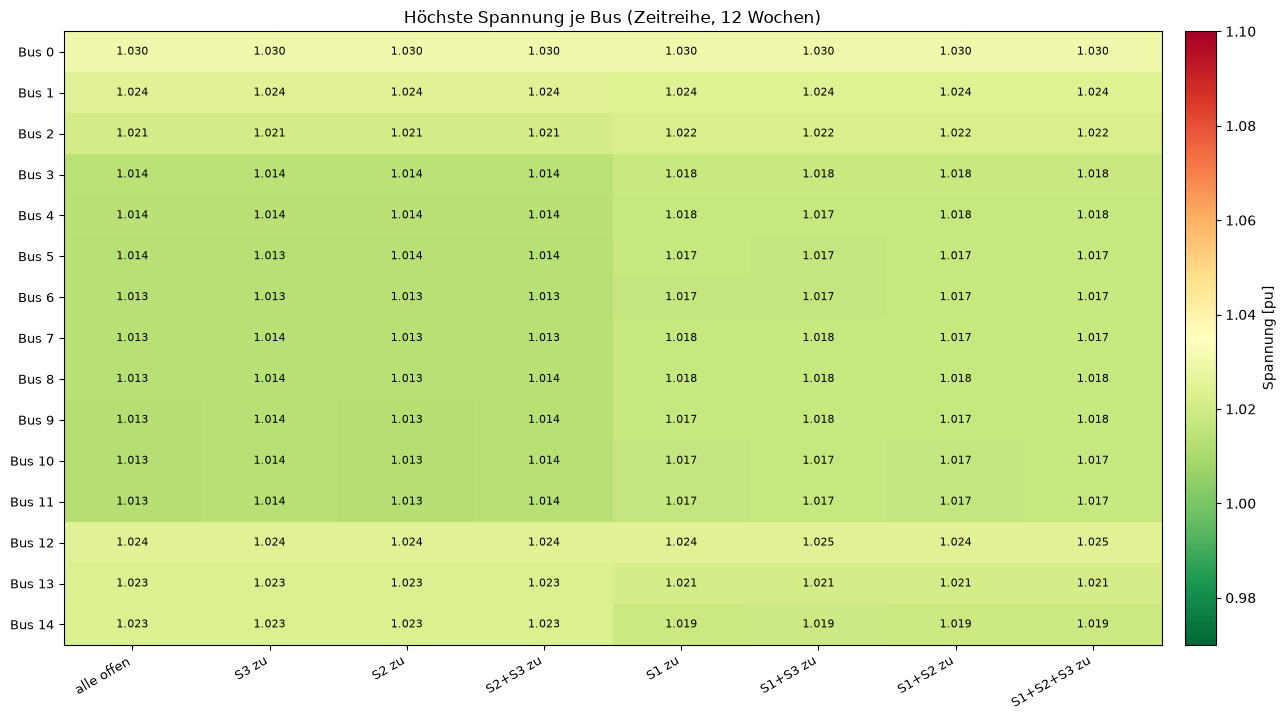

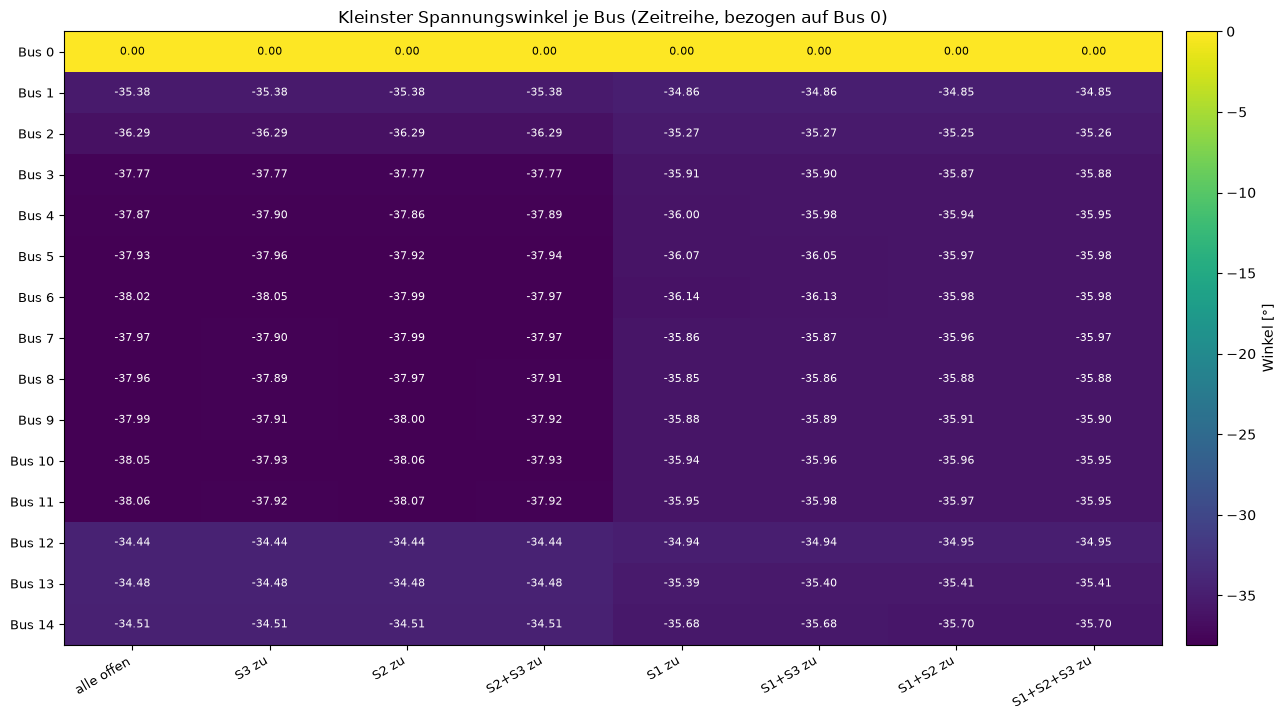

In [23]:
sz.heatmap(sz.je_element(ts, "vm_pu", "min"), "Niedrigste Spannung je Bus (Zeitreihe, 12 Wochen)",
           "Spannung [pu]", cmap="RdYlGn", vmin=0.90, vmax=1.03, fmt="{:.3f}")
plt.show()
sz.heatmap(sz.je_element(ts, "vm_pu", "max"), "Höchste Spannung je Bus (Zeitreihe, 12 Wochen)",
           "Spannung [pu]", cmap="RdYlGn_r", vmin=0.97, vmax=1.10, fmt="{:.3f}")
plt.show()
sz.heatmap(sz.je_element(ts, "va_degree", "min"), "Kleinster Spannungswinkel je Bus (Zeitreihe, bezogen auf Bus 0)",
           "Winkel [°]", cmap="viridis", fmt="{:.2f}")
plt.show()

**Höchste Auslastung je Leitung und Trafo über das Jahr:**

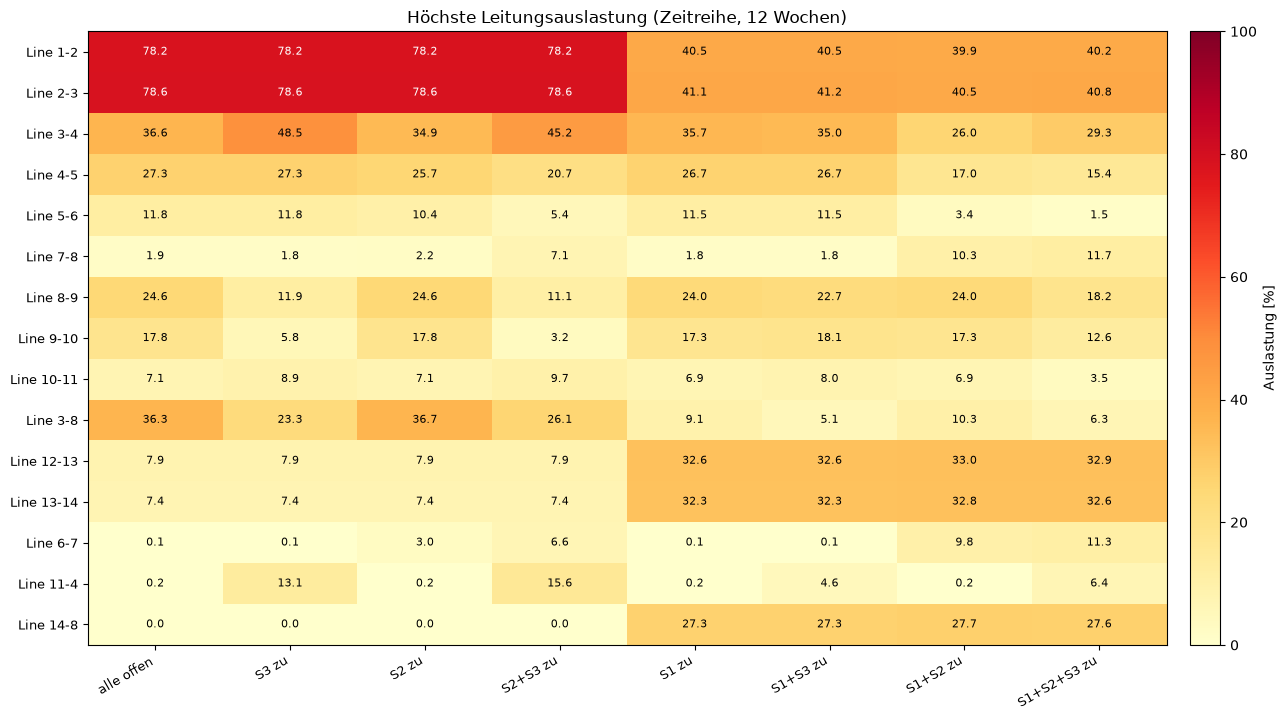

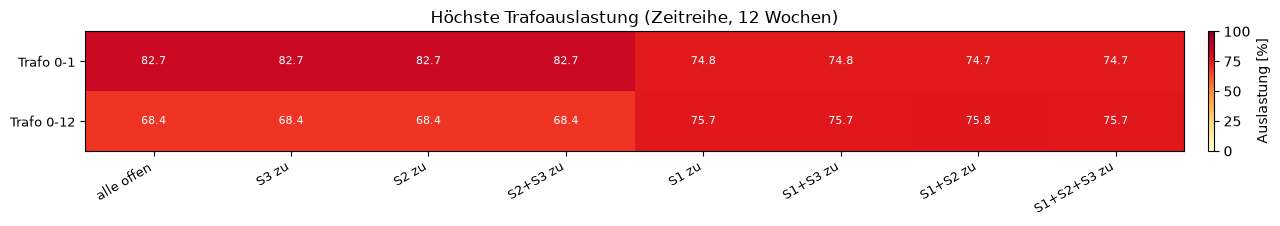

In [24]:
sz.heatmap(sz.je_element(ts, "line_loading", "max"), "Höchste Leitungsauslastung (Zeitreihe, 12 Wochen)",
           "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
sz.heatmap(sz.je_element(ts, "trafo_loading", "max"), "Höchste Trafoauslastung (Zeitreihe, 12 Wochen)",
           "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()

**Zeitverlauf in der Januarwoche** (höchste Last) für den schwächsten Bus und die beiden Transformatoren, Normalbetrieb im Vergleich zu geschlossenem S1:

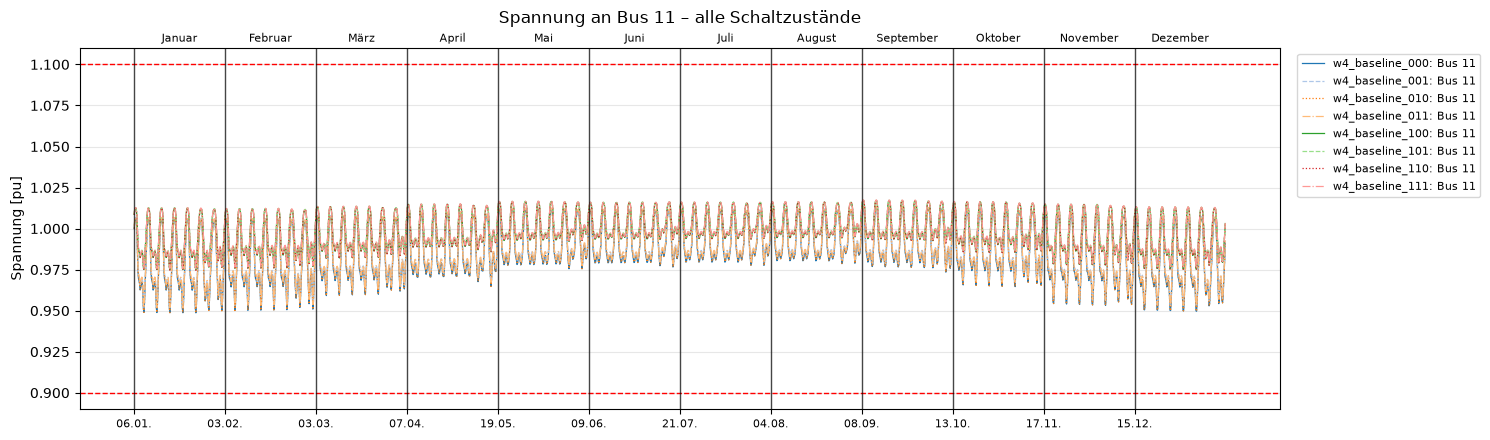

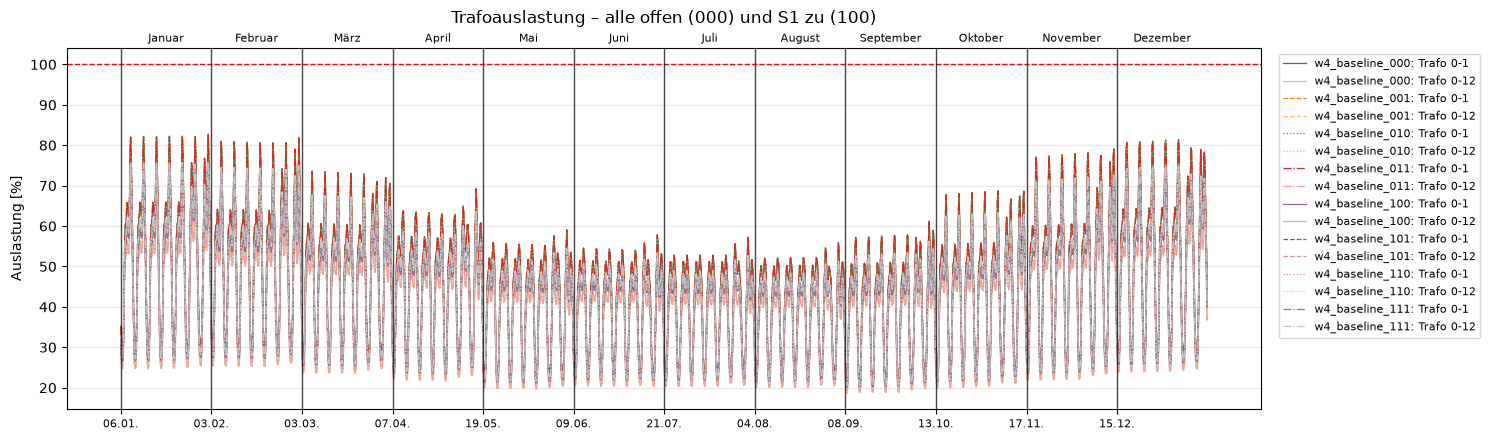

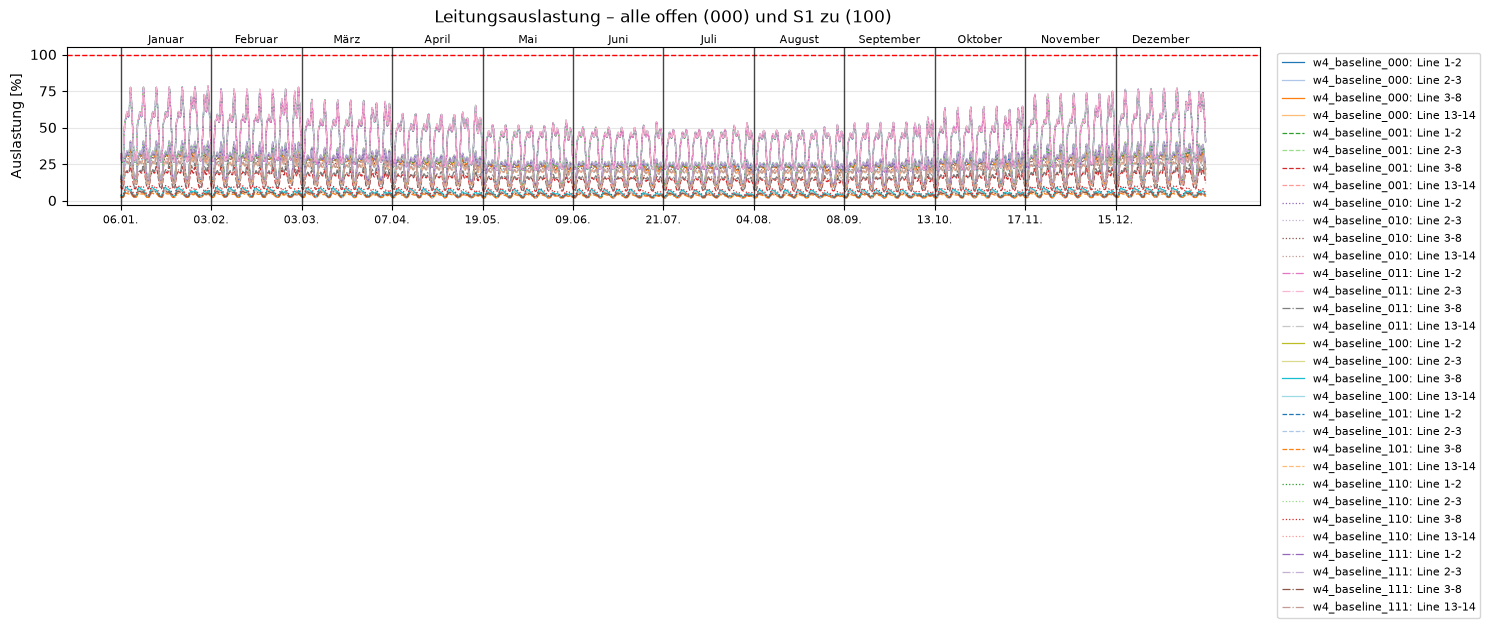

In [30]:
sim.compare([ts[k] for k in sz.KEYS], Diagram.VOLTAGE, ["Bus 11"], layout="overview",
            title="Spannung an Bus 11 – alle Schaltzustände")
sim.compare([ts[k] for k in sz.KEYS], Diagram.TRAFO_LOADING, None, layout="overview",
            title="Trafoauslastung – alle offen (000) und S1 zu (100)")
sim.compare([ts[k] for k in sz.KEYS], Diagram.LINE_LOADING, ["Line 1-2", "Line 2-3", "Line 3-8", "Line 13-14"],
            layout="overview", title="Leitungsauslastung – alle offen (000) und S1 zu (100)")

**Netzplan zum Zeitpunkt der höchsten Leitungsauslastung** im Normalbetrieb und mit geschlossenem S1:

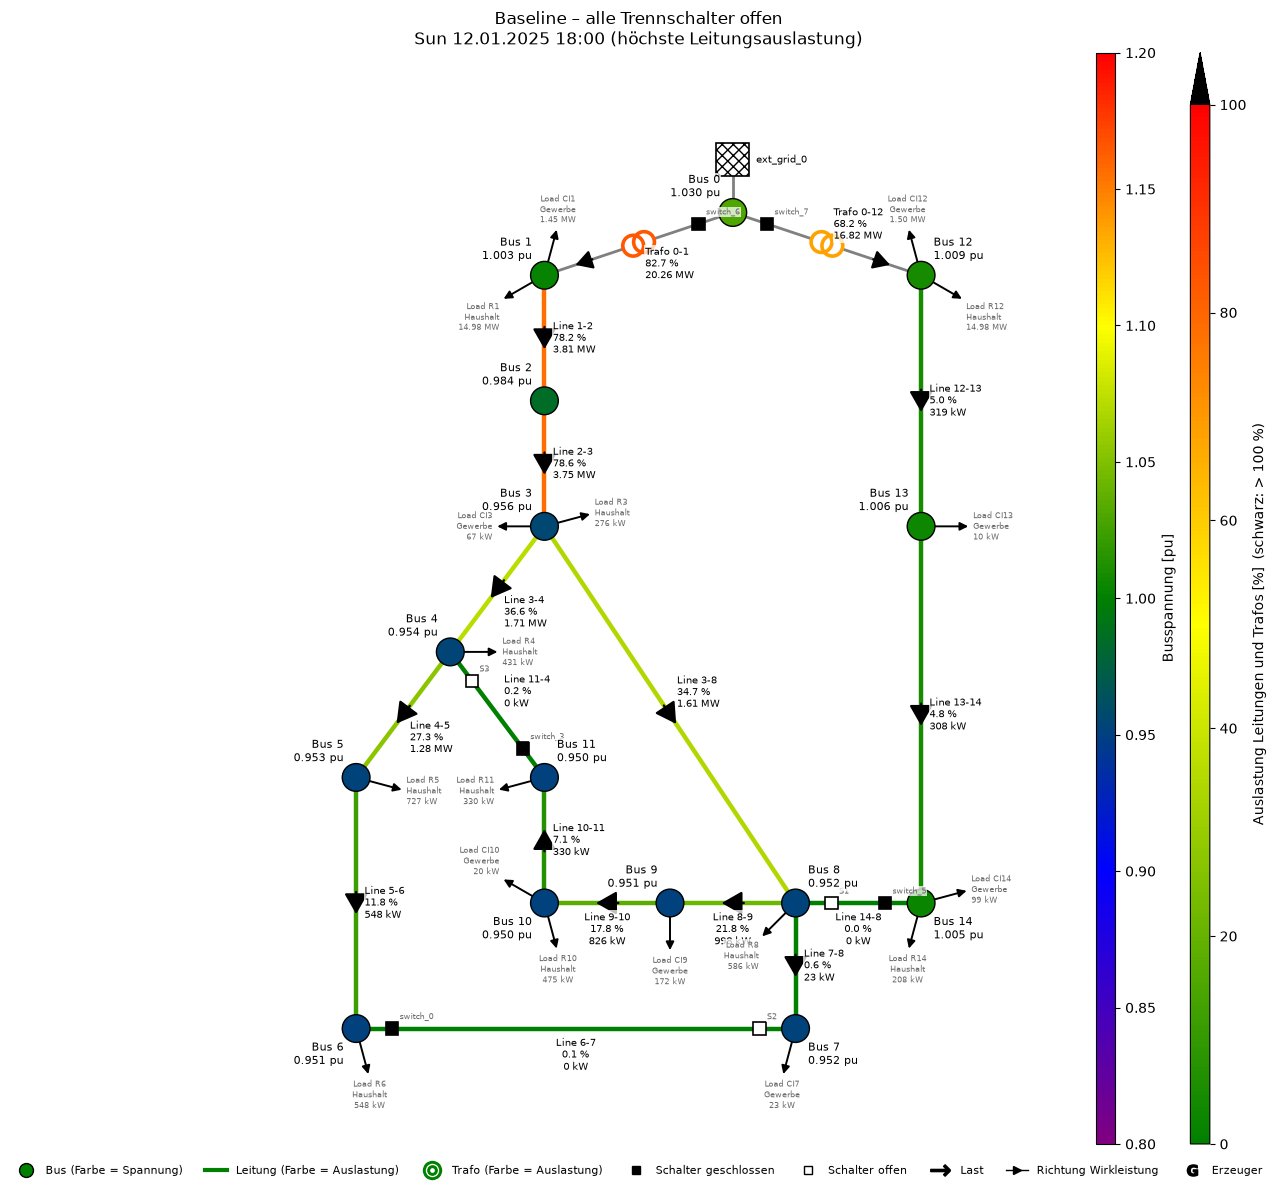

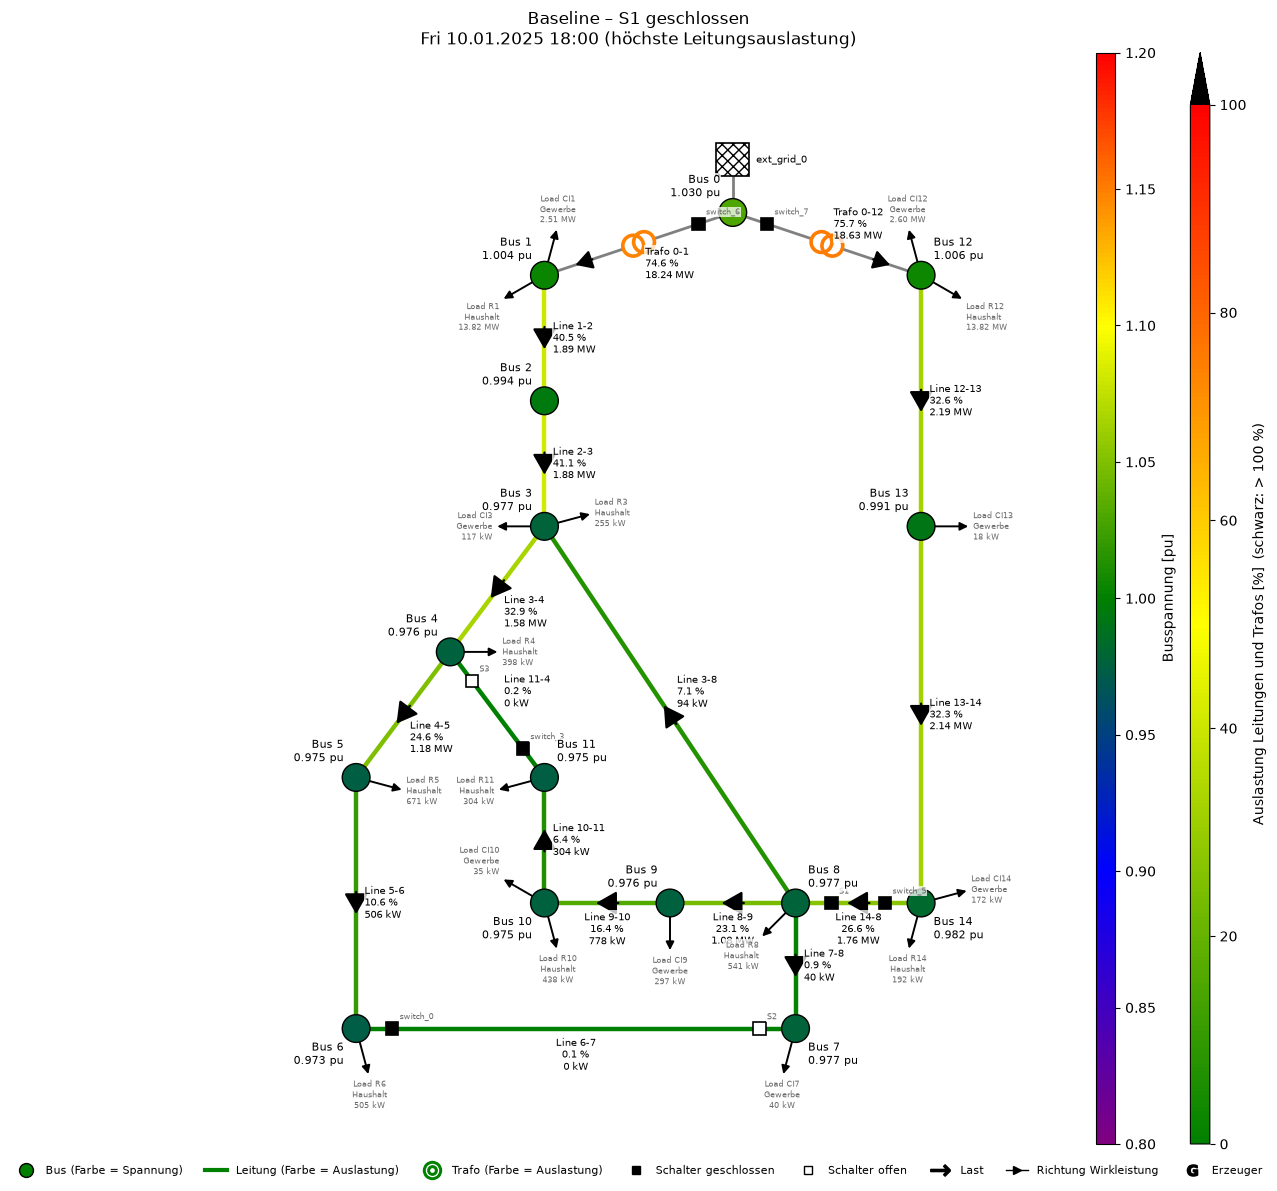

In [26]:
ts["000"].createDiagram(Diagram.NETWORK, time="max_loading", title="Baseline – alle Trennschalter offen")
ts["100"].createDiagram(Diagram.NETWORK, time="max_loading", title="Baseline – S1 geschlossen")

**Interpretation (Zeitreihe):**

- **Keine Grenzverletzung:** In keinem Schaltzustand und keiner Stunde wird das Band 0,90 bis 1,10 pu verletzt oder ein Betriebsmittel über 100 % belastet. Die niedrigste Spannung liegt im Normalbetrieb bei 0,949 pu (Bus 11, Freitag 10.01. 18:00), die höchste Leitungsauslastung bei 78,6 % (Line 2-3) und die höchste Trafoauslastung bei 82,7 % (Trafo 0-1).
- **Unterschied zum statischen Fall:** Die Zeitreihe erreicht nicht die 97 % bzw. 101 % des statischen Falls. Ursache ist die Gleichzeitigkeit: Haushalts- und Gewerbelasten haben ihre Spitzen zu unterschiedlichen Zeiten, und die Haushaltsspitze tritt nur an wenigen Winterabenden auf.
- **Wirkung der Schalter:** Das Muster des statischen Falls bestätigt sich über das ganze Jahr. S1 halbiert die Auslastung von Line 1-2 und Line 2-3 (78,6 % → 41 %), hebt die niedrigste Spannung auf 0,973 bis 0,975 pu und senkt die Verluste über die 12 Wochen von 141 MWh auf 107 MWh (−24 %). Dafür steigt die Belastung der Freileitungen in Abgang 2 auf etwa 33 % und ihre Spannung sinkt. S2 und S3 verschieben nur die Aufteilung innerhalb von Abgang 1.
- **Höchste Spannung:** Ohne Erzeuger liegt die höchste 20-kV-Spannung bei 1,024 pu in Schwachlaststunden (Nacht, Sommer) knapp unter der Slack-Spannung von 1,03 pu. Rückspeisung tritt ohne Erzeuger nicht auf.

## 5 Referenzszenario

Für alle weiteren Teilaufgaben wird folgendes Referenzszenario festgelegt:

| Größe | Festlegung | in späteren Szenarien |
|---|---|---|
| Netz | `pn.create_cigre_network_mv(with_der=False)`, Funktion `baseline_net()` | Grundlage, wird je Szenario gezielt ergänzt |
| Schalter | S1, S2, S3 offen (Schlüssel `000`); alle Kombinationen über `szenarien.py` | wird je Untersuchung über alle 8 Zustände variiert |
| externes Netz | Bus 0, 1,03 pu, 0° | konstant |
| Transformatoren | 2 × 25 MVA, 110/20 kV, vk = 12 %, ohne Stufenschalter | konstant (Stufenschalter nur am Ortsnetztrafo, Teil 3) |
| Leitungen | Parameter nach [13] | konstant, außer bei der Kapazitätserhöhung in Teil 6 |
| Lasten | 18 CIGRE-Lasten, H25 (R) bzw. G25 (CI), Jahreshöchstleistung = `p_mw` aus [13] | konstant |
| Erzeuger | keine | Windpark, Großflächen-PV, Ortsnetz (Teile 2 und 4) |
| Zeitbasis | 12 typische Wochen 2025, stündlich, 2016 Zeitpunkte | konstant |
| Grenzen | 0,90 / 1,10 pu, 100 % thermisch | Planungsband wird in Teil 3 ergänzt |
| Lastfluss | Newton-Raphson, nicht konvergierte Zeitpunkte als NaN gekennzeichnet | konstant |

Die Referenz-Zeitreihen sind als Simulationen `w4_baseline_000` bis `w4_baseline_111` gespeichert. Ein neues Szenario startet immer von einer Kopie:

```python
ref = sim.loadSimulation("w4_baseline_000")        # oder baseline aus diesem Notebook
windpark = ref.copy("w4_windpark", overwrite=True)  # Baseline der Kopie = Referenz
windpark.createElement(...)                         # nur die Änderung des Szenarios
windpark.changedElements()                          # dokumentiert, was verändert wurde
```

`changedElements()` und `changedParameters()` zeigen jederzeit, was gegenüber der Referenz verändert wurde.

In [27]:
ref = sim.loadSimulation("w4_baseline_000")
print(ref)
print("Änderungen gegenüber der Baseline:", len(ref.changedParameters()), "Parameter,", len(ref.changedElements()), "Elemente")

Simulation 'w4_baseline_000' (15 bus, 15 line, 2 trafo, 1 ext_grid, 8 switch, 18 load)
  Herkunft: w4_baseline | Änderungen: 0 | Ergebnisse: aktuell | letzter Lauf: 2026-10-28T14:44:03
Änderungen gegenüber der Baseline: 0 Parameter, 0 Elemente


## 6 Zusammenfassung und Literaturabgleich

- **Spannungsband:** Das unveränderte CIGRE-MV-Netz hält in allen 8 Schaltzuständen, statisch wie in der Zeitreihe, die Arbeitsgrenzen 0,90 bis 1,10 pu ein. DIN EN 50160 fordert für Mittelspannungsnetze, dass 99 % der 10-Minuten-Mittelwerte einer Woche innerhalb von ±10 % der vereinbarten Versorgungsspannung liegen [15]. Der Spannungsfall bis zum Ende von Abgang 1 beträgt im Normalbetrieb aber bis zu 7,7 % (statisch) bzw. 5,1 % (Zeitreihe). Für nachgelagerte Ortsnetze bleibt damit wenig Reserve. Das ist für Teil 2 und 3 (Ortsnetz, regelbarer Ortsnetztrafo) wichtig.
- **Thermische Grenzen:** Engpässe sind der Trafo 0-1 und die Kabel Line 1-2 und Line 2-3. Im statischen Grenzfall ist Trafo 0-1 leicht überlastet. In der Zeitreihe bleiben alle Betriebsmittel wegen der geringeren Gleichzeitigkeit unter 83 %.
- **Schalterstellungen:** Die Kupplung S1 entlastet Abgang 1 und senkt die Verluste deutlich, vermascht aber beide Abgänge über die 110-kV-Ebene. S2 und S3 verschieben die Last nur innerhalb von Abgang 1. Der strahlenförmige Normalbetrieb mit offenen Trennstellen entspricht der üblichen Betriebsweise von Mittelspannungsnetzen [16]. Die offenen Ringe dienen der Wiederversorgung, nicht der dauerhaften Lastaufteilung.
- **Verluste:** 0,68 % der Last im statischen Fall, 0,32 % über die Zeitreihe. Die Verluste steigen quadratisch mit dem Strom. Deshalb liegen sie im Spitzenlastfall relativ höher.
- **Baseline:** Das Referenzszenario in Abschnitt 5 legt fest, was in den späteren Teilaufgaben verändert wird und was konstant bleibt.

### Quellen

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

[15] DIN EN 50160, „Merkmale der Spannung in öffentlichen Elektrizitätsversorgungsnetzen“ (EN 50160:2010 mit Änderungen), Berlin: Beuth.

[16] K. Heuck, K.-D. Dettmann und D. Schulz, *Elektrische Energieversorgung: Erzeugung, Übertragung und Verteilung elektrischer Energie für Studium und Praxis*, 9. Aufl. Wiesbaden: Springer Vieweg, 2013.

[17] pandapower, „Datastructure and Elements“, Dokumentation der Ergebnistabellen (res_bus, res_line, res_trafo, res_ext_grid). Online: https://pandapower.readthedocs.io/en/latest/elements.html

*Seiten bzw. Kapitel von [13] und [16] sowie die Ausgabe von [15] anhand der verwendeten Ausgabe ergänzen.*